# Hospitality Customer Segmentation - end-to-end notebook
Synthetic hospitality data -> feature engineering -> EDA -> **6 segmentation models** (GPU) -> evaluation -> best-model selection.
All artifacts (logs, plots at 300 DPI, saved models, benchmark tables) are written to `output/`.
The FastAPI service is intentionally **not** part of this notebook.

Set `QUICK = True` for a fast smoke run.

In [1]:
QUICK = False      # True -> small epochs / 4k guests
FORCE_CPU = False
import warnings; warnings.filterwarnings("ignore")
import argparse, datetime as dt, json, time, joblib, logging, random, sys
from contextlib import contextmanager
from pathlib import Path
import numpy as np, pandas as pd, yaml, torch
import torch.nn as nn, torch.nn.functional as F
import matplotlib; matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt, seaborn as sns
%matplotlib inline

## 1. Utilities - device, logging, seeding, JSONL metrics

In [2]:
import json
import logging
import random
import sys
import time
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import yaml

ROOT = Path.cwd()
_LOGGER_NAME = "segmentation"


def load_config(path=None):
    path = Path(path) if path else ROOT / "config" / "config.yaml"
    with open(path, "r", encoding="utf-8") as f:
        return yaml.safe_load(f)


def out_dir(cfg=None, *parts):
    base = ROOT / ((cfg or {}).get("paths", {}).get("output", "output"))
    p = base.joinpath(*parts)
    p.mkdir(parents=True, exist_ok=True)
    return p


def ensure_output_dirs(cfg=None):
    for sub in ["logs", "data_visualizations", "feature_visualizations", "training_losses",
                "model_comparisons", "saved_models", "api_screenshots"]:
        out_dir(cfg, sub)


def get_logger(name=_LOGGER_NAME, logfile="pipeline_execution.log", cfg=None):
    """Logger streaming to console and output/logs/<logfile>."""
    logger = logging.getLogger(name)
    if logger.handlers:
        return logger
    logger.setLevel(logging.INFO)
    fmt = logging.Formatter("%(asctime)s | %(levelname)-7s | %(name)s | %(message)s")
    try:
        sys.stdout.reconfigure(encoding="utf-8", errors="replace")
    except Exception:
        pass
    sh = logging.StreamHandler(sys.stdout)
    sh.setFormatter(fmt)
    logger.addHandler(sh)
    fh = logging.FileHandler(out_dir(cfg, "logs") / logfile, encoding="utf-8")
    fh.setFormatter(fmt)
    logger.addHandler(fh)
    logger.propagate = False
    return logger


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


def get_device(use_gpu=True, logger=None):
    import torch
    log = logger or get_logger()
    if use_gpu and torch.cuda.is_available():
        dev = torch.device("cuda")
        props = torch.cuda.get_device_properties(0)
        log.info("CUDA device: %s | VRAM total %.1f GB | torch %s | CUDA %s",
                 props.name, props.total_memory / 1e9, torch.__version__, torch.version.cuda)
    else:
        dev = torch.device("cpu")
        log.warning("Running on CPU (%s)", "GPU disabled by flag" if not use_gpu else "CUDA not available")
    return dev


def log_gpu_memory(tag="", logger=None):
    import torch
    if torch.cuda.is_available():
        (logger or get_logger()).info("GPU mem [%s]: allocated %.1f MB | reserved %.1f MB", tag,
                                      torch.cuda.memory_allocated() / 1e6, torch.cuda.memory_reserved() / 1e6)


@contextmanager
def timed(label, logger=None):
    log = logger or get_logger()
    t0 = time.perf_counter()
    log.info("START %s", label)
    try:
        yield
    finally:
        log.info("END   %s (%.2fs)", label, time.perf_counter() - t0)


def sync():
    import torch
    if torch.cuda.is_available():
        torch.cuda.synchronize()


class JsonlMetricsLogger:
    """Append structured per-epoch records to output/logs/training_metrics.jsonl."""

    def __init__(self, cfg=None, filename="training_metrics.jsonl"):
        self.path = out_dir(cfg, "logs") / filename

    def log(self, **record):
        record["ts"] = time.strftime("%Y-%m-%dT%H:%M:%S")
        with open(self.path, "a", encoding="utf-8") as f:
            f.write(json.dumps(record, default=float) + "\n")

    def read(self, model=None, phase=None):
        rows = []
        if self.path.exists():
            with open(self.path, encoding="utf-8") as f:
                for line in f:
                    r = json.loads(line)
                    if (model is None or r.get("model") == model) and (phase is None or r.get("phase") == phase):
                        rows.append(r)
        return rows


def grad_norm(model):
    total = 0.0
    for p in model.parameters():
        if p.grad is not None:
            total += p.grad.detach().norm(2).item() ** 2
    return total ** 0.5

## 2. Synthetic hospitality data generator (25k guests, 120k+ stays)

In [3]:
import numpy as np
import pandas as pd


REF_DATE = pd.Timestamp("2026-11-01")
PROPERTY_TYPES = ["Urban Business", "Resort/Leisure", "Boutique", "Extended Stay"]
LOYALTY = ["Member", "Silver", "Gold", "Platinum", "Ambassador"]
REGIONS = ["North America", "Europe", "APAC", "Middle East", "Latin America"]
AGES = ["18-29", "30-44", "45-59", "60+"]
ROOM_TIERS = ["Standard", "Deluxe", "Suite", "Villa"]

ARCH_NAMES = ["Corporate Road Warriors", "Luxury Resort Families", "Weekend Spa Couples",
              "OTA Price-Sensitive Travelers", "At-Risk Dormant VIPs"]

# Archetype parameter table.
ARCH = {
    0: dict(p=0.25, stays=7, gap=40, adr=210, nights=2.0, lead=7, wk=0.15, rec=25,
            prop=[.75, .03, .07, .15], loy=[.05, .2, .35, .3, .1], room=[.35, .45, .18, .02],
            spa=.03, dine=.15, golf=.02, biz=.75, app=.55, ota=.12, email=.55, key=.7, redeem=.15,
            cancel=.06, lastmin=.4, trend=0.0, age=[.05, .45, .4, .1], tenure=70),
    1: dict(p=0.18, stays=3, gap=120, adr=460, nights=5.5, lead=75, wk=0.45, rec=110,
            prop=[.02, .8, .13, .05], loy=[.05, .15, .3, .3, .2], room=[.05, .2, .45, .3],
            spa=.14, dine=.32, golf=.18, biz=.03, app=.4, ota=.15, email=.5, key=.4, redeem=.2,
            cancel=.1, lastmin=.05, trend=0.0, age=[.02, .38, .45, .15], tenure=60),
    2: dict(p=0.17, stays=4, gap=90, adr=330, nights=2.3, lead=35, wk=0.85, rec=70,
            prop=[.03, .35, .55, .07], loy=[.1, .3, .3, .2, .1], room=[.1, .45, .38, .07],
            spa=.38, dine=.22, golf=.03, biz=.02, app=.5, ota=.2, email=.6, key=.55, redeem=.12,
            cancel=.08, lastmin=.12, trend=0.0, age=[.2, .5, .25, .05], tenure=45),
    3: dict(p=0.25, stays=2.5, gap=150, adr=115, nights=2.4, lead=22, wk=0.5, rec=150,
            prop=[.3, .2, .15, .35], loy=[.65, .22, .08, .04, .01], room=[.75, .22, .03, 0.0],
            spa=.02, dine=.06, golf=.01, biz=.12, app=.08, ota=.8, email=.2, key=.2, redeem=.03,
            cancel=.28, lastmin=.2, trend=0.0, age=[.35, .4, .2, .05], tenure=20),
    4: dict(p=0.15, stays=6, gap=70, adr=520, nights=3.5, lead=45, wk=0.4, rec=520,
            prop=[.25, .35, .3, .1], loy=[.0, .05, .2, .35, .4], room=[.02, .18, .5, .3],
            spa=.12, dine=.25, golf=.1, biz=.2, app=.3, ota=.1, email=.12, key=.3, redeem=.08,
            cancel=.12, lastmin=.1, trend=1.0, age=[.0, .2, .45, .35], tenure=110),
}


def generate_dataset(n_guests=25000, seq_len=10, seed=42, overlap=0.12):
    """Return (guests_df, events_df, seq_tensor (N,L,4), seq_mask (N,L), archetype_ids)."""
    rng = np.random.default_rng(seed)
    probs = np.array([ARCH[i]["p"] for i in range(5)])
    arch = rng.choice(5, size=n_guests, p=probs / probs.sum())
    # Profile "blur": a fraction of guests behave like another archetype -> realistic overlap.
    behave = arch.copy()
    flip = rng.random(n_guests) < overlap
    behave[flip] = rng.integers(0, 5, flip.sum())

    ev_rows, guests = [], []
    seq = np.zeros((n_guests, seq_len, 4), dtype=np.float32)
    mask = np.zeros((n_guests, seq_len), dtype=np.float32)

    for g in range(n_guests):
        a = ARCH[int(behave[g])]
        n = max(1, int(rng.poisson(a["stays"] * rng.lognormal(0, 0.25))) + 1)
        # newest stay first
        rec = max(1, rng.gamma(2.0, a["rec"] / 2.0))
        gaps = rng.gamma(2.0, a["gap"] / 2.0, n)
        if a["trend"]:  # dormant: gaps widen & spend falls towards the present
            gaps = gaps * np.linspace(2.2, 0.6, n)
        gaps[0] = rec
        days_ago = np.cumsum(gaps)
        nights = np.clip(rng.poisson(a["nights"] * rng.lognormal(0, .2), n), 1, 21)
        adr_g = a["adr"] * rng.lognormal(0, .18)
        adr = adr_g * rng.lognormal(0, .08, n)
        if a["trend"]:
            adr = adr * np.linspace(0.7, 1.15, n)
        lead = np.clip(rng.gamma(2.0, a["lead"] / 2.0 * rng.lognormal(0, .2), n), 0, 365)
        prop = rng.choice(4, size=n, p=a["prop"])
        anc = a["spa"] + a["dine"] + a["golf"]
        spend = nights * adr * (1 + anc * rng.lognormal(0, .3, n) * 3)
        for i in range(n):
            ev_rows.append((g, REF_DATE - pd.Timedelta(days=float(days_ago[i])), prop[i], nights[i],
                            adr[i], spend[i], lead[i]))
        # sequence: chronological order, last seq_len stays, padded at front
        take = np.arange(min(n, seq_len))  # indices 0..k-1 are newest..older
        chron = take[::-1]
        da = days_ago[chron]
        gap = np.concatenate([[0.0], -np.diff(da)])
        k = len(chron)
        seq[g, seq_len - k:, 0] = gap
        seq[g, seq_len - k:, 1] = spend[chron]
        seq[g, seq_len - k:, 2] = prop[chron]
        seq[g, seq_len - k:, 3] = lead[chron]
        mask[g, seq_len - k:] = 1

        # guest-level behavioural ratios
        def r(x, s=0.25):
            return float(np.clip(x * rng.lognormal(0, s), 0, 1))
        app, ota = r(a["app"]), r(a["ota"])
        tot = app + ota
        if tot > 0.98:
            app, ota = app / tot * .98, ota / tot * .98
        loy = rng.choice(5, p=a["loy"])
        guests.append(dict(
            guest_id=g, loyalty_tier=LOYALTY[loy],
            tenure_months=float(np.clip(rng.gamma(3, a["tenure"] / 3), 1, 240)),
            home_region=rng.choice(REGIONS, p=[.35, .25, .2, .1, .1]),
            age_group=AGES[rng.choice(4, p=a["age"])],
            room_tier_preference=ROOM_TIERS[rng.choice(4, p=a["room"])],
            property_type_affinity=PROPERTY_TYPES[int(np.bincount(prop, minlength=4).argmax())],
            weekend_vs_weekday_ratio=float(np.clip(a["wk"] + rng.normal(0, .12), 0, 1)),
            cancellation_rate=r(a["cancel"], .4), last_minute_booking_ratio=r(a["lastmin"], .35),
            spa_spend_ratio=r(a["spa"], .4), dining_fb_spend_ratio=r(a["dine"], .35),
            golf_recreation_spend_ratio=r(a["golf"], .5),
            business_center_usage=r(a["biz"], .35),
            direct_app_booking_ratio=app, ota_booking_ratio=ota,
            email_open_rate=r(a["email"], .3), mobile_key_usage_rate=r(a["key"], .3),
            points_redemption_rate=r(a["redeem"], .5),
            true_archetype=int(arch[g]),
        ))

    events = pd.DataFrame(ev_rows, columns=["guest_id", "stay_date", "property_type_id",
                                            "nights", "adr", "spend", "lead_time_days"])
    events["stay_date"] = pd.to_datetime(events["stay_date"])
    guests = pd.DataFrame(guests)

    # Aggregate RFM-style features from events (consistent with the event log)
    last12 = events[events.stay_date >= REF_DATE - pd.Timedelta(days=365)]
    agg = events.groupby("guest_id").agg(
        recency_days=("stay_date", lambda s: (REF_DATE - s.max()).days),
        monetary_total_spend=("spend", "sum"), avg_daily_rate=("adr", "mean"),
        avg_length_of_stay=("nights", "mean"), booking_lead_time_days=("lead_time_days", "mean"),
        total_stays=("spend", "size"))
    freq = last12.groupby("guest_id").size().rename("frequency_stays_12m")
    guests = guests.merge(agg, left_on="guest_id", right_index=True).merge(
        freq, left_on="guest_id", right_index=True, how="left")
    guests["frequency_stays_12m"] = guests["frequency_stays_12m"].fillna(0)
    return guests, events, seq, mask


def build_and_save(cfg=None, n_guests=None):
    cfg = cfg or load_config()
    log = get_logger(cfg=cfg)
    set_seed(cfg["seed"])
    n = n_guests or cfg["data"]["n_guests"]
    guests, events, seq, mask = generate_dataset(n, cfg["data"]["seq_len"], cfg["seed"])
    d = ROOT / cfg["paths"]["data"]
    d.mkdir(parents=True, exist_ok=True)
    guests.to_csv(d / "guests.csv", index=False)
    events.to_csv(d / "stay_events.csv", index=False)
    np.savez_compressed(d / "sequences.npz", seq=seq, mask=mask)
    log.info("Data generated: guests %s | events %s | sequences %s", guests.shape, events.shape, seq.shape)
    return guests, events, seq, mask


if __name__ == "__main__":
    build_and_save()

2026-11-20 11:11:11,203 | INFO    | segmentation | Data generated: guests (25000, 27) | events (141077, 7) | sequences (25000, 10, 4)


## 3. Feature engineering (RFM, behavioural, ancillary, channel, temporal) + sequence normaliser

In [4]:
import joblib
import numpy as np
import pandas as pd
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler


LOG_COLS = ["monetary_total_spend", "recency_days", "avg_daily_rate", "booking_lead_time_days",
            "avg_length_of_stay", "tenure_months", "frequency_stays_12m"]
NUM_COLS = LOG_COLS + [
    "weekend_vs_weekday_ratio", "cancellation_rate", "last_minute_booking_ratio",
    "spa_spend_ratio", "dining_fb_spend_ratio", "golf_recreation_spend_ratio", "business_center_usage",
    "direct_app_booking_ratio", "ota_booking_ratio", "email_open_rate", "mobile_key_usage_rate",
    "points_redemption_rate", "spend_per_stay", "ancillary_total_ratio", "stay_velocity",
    "digital_engagement", "other_channel_ratio"]
ORD_COLS = ["loyalty_tier"]
OHE_COLS = ["room_tier_preference", "property_type_affinity", "age_group", "home_region"]


def engineer_features(g: pd.DataFrame) -> pd.DataFrame:
    df = g.copy()
    df["spend_per_stay"] = df["monetary_total_spend"] / df["total_stays"].clip(lower=1)
    df["ancillary_total_ratio"] = df[["spa_spend_ratio", "dining_fb_spend_ratio",
                                      "golf_recreation_spend_ratio"]].sum(axis=1)
    df["stay_velocity"] = df["total_stays"] / (df["tenure_months"].clip(lower=1) / 12.0)
    df["digital_engagement"] = (df["email_open_rate"] + df["mobile_key_usage_rate"]
                                + df["direct_app_booking_ratio"]) / 3
    df["other_channel_ratio"] = (1 - df["direct_app_booking_ratio"] - df["ota_booking_ratio"]).clip(lower=0)
    return df


def _log(X):
    return np.log1p(np.clip(X, 0, None))


class FeaturePipeline:
    """Fit/transform wrapper that exposes `scaler` and `encoder` for joblib persistence."""

    def __init__(self):
        self.scaler = StandardScaler()
        self.ord_enc = OrdinalEncoder(categories=[LOYALTY])
        self.encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
        self.extra_log = ["spend_per_stay", "stay_velocity"]
        self.feature_names_ = None

    def _numeric(self, df):
        X = df[NUM_COLS].copy()
        for c in LOG_COLS + self.extra_log:
            X[c] = _log(X[c].values)
        return X

    def fit_transform(self, df):
        df = engineer_features(df) if "spend_per_stay" not in df else df
        num = self.scaler.fit_transform(self._numeric(df))
        ordv = self.ord_enc.fit_transform(df[ORD_COLS]) / 4.0
        ohe = self.encoder.fit_transform(df[OHE_COLS])
        self.feature_names_ = NUM_COLS + ORD_COLS + list(self.encoder.get_feature_names_out(OHE_COLS))
        return np.hstack([num, ordv, ohe]).astype(np.float32)

    def transform(self, df):
        df = engineer_features(df) if "spend_per_stay" not in df else df
        num = self.scaler.transform(self._numeric(df))
        ordv = self.ord_enc.transform(df[ORD_COLS]) / 4.0
        ohe = self.encoder.transform(df[OHE_COLS])
        return np.hstack([num, ordv, ohe]).astype(np.float32)

    def save(self, folder):
        joblib.dump(self.scaler, folder / "scaler.joblib")
        joblib.dump({"ordinal": self.ord_enc, "onehot": self.encoder}, folder / "encoder.joblib")
        joblib.dump(self, folder / "feature_pipeline.joblib")

    @staticmethod
    def load(folder):
        return joblib.load(folder / "feature_pipeline.joblib")


class SequenceNormalizer:
    """log1p + standardise (gap, spend, lead); property id kept as categorical index."""

    def fit(self, seq, mask):
        x = self._pre(seq)
        m = mask.astype(bool)
        self.mean_ = np.array([x[..., c][m].mean() for c in (0, 1, 3)], dtype=np.float32)
        self.std_ = np.array([x[..., c][m].std() + 1e-6 for c in (0, 1, 3)], dtype=np.float32)
        return self

    @staticmethod
    def _pre(seq):
        x = seq.copy()
        for c in (0, 1, 3):
            x[..., c] = np.log1p(np.clip(x[..., c], 0, None))
        return x

    def transform(self, seq, mask):
        """Returns (cont (N,L,3), prop_ids (N,L) long, mask)."""
        x = self._pre(seq)
        cont = np.stack([(x[..., c] - self.mean_[i]) / self.std_[i] for i, c in enumerate((0, 1, 3))], -1)
        cont = cont * mask[..., None]
        return cont.astype(np.float32), seq[..., 2].astype(np.int64), mask.astype(np.float32)

## 4. Classical ML - GPU K-Means, GMM (EM), HDBSCAN

In [5]:
import joblib
import numpy as np
import torch
from sklearn.decomposition import PCA


log = get_logger()

try:  # RAPIDS (Linux / WSL2 only)
    from cuml.cluster import KMeans as CuKMeans  # type: ignore
    HAS_CUML = True
except Exception:
    HAS_CUML = False

try:
    import hdbscan as _hdbscan_pkg  # type: ignore
except Exception:
    _hdbscan_pkg = None


def _t(X, device):
    return torch.as_tensor(np.asarray(X), dtype=torch.float32, device=device)


def _sqdist(X, C, chunk=16384):
    out = []
    for i in range(0, X.shape[0], chunk):
        out.append(torch.cdist(X[i:i + chunk], C) ** 2)
    return torch.cat(out)


class KMeansGPU:
    """K-Means (k-means++ init, Lloyd iterations) on the GPU via PyTorch; cuML if available."""

    def __init__(self, n_clusters=5, n_init=3, max_iter=100, tol=1e-4, seed=42, device=None):
        self.k, self.n_init, self.max_iter, self.tol, self.seed = n_clusters, n_init, max_iter, tol, seed
        self.device = device or torch.device("cpu")
        self.centers_ = None

    def _init_pp(self, X, gen):
        n = X.shape[0]
        idx = torch.randint(0, n, (1,), generator=gen, device="cpu").item()
        C = X[idx:idx + 1]
        for _ in range(1, self.k):
            d = _sqdist(X, C).min(1).values
            p = (d / d.sum()).clamp_min(1e-12).cpu()
            idx = torch.multinomial(p, 1, generator=gen).item()
            C = torch.cat([C, X[idx:idx + 1]])
        return C

    def fit(self, X):
        if HAS_CUML and self.device.type == "cuda":
            log.info("KMeans: using cuML backend")
            km = CuKMeans(n_clusters=self.k, random_state=self.seed, n_init=self.n_init).fit(np.asarray(X))
            self.centers_ = _t(km.cluster_centers_, self.device)
            return self
        X = _t(X, self.device)
        gen = torch.Generator().manual_seed(self.seed)
        best = (float("inf"), None)
        for _ in range(self.n_init):
            C = self._init_pp(X, gen)
            prev = float("inf")
            for _ in range(self.max_iter):
                d = _sqdist(X, C)
                lab = d.argmin(1)
                inertia = d.gather(1, lab[:, None]).sum().item()
                newC = torch.zeros_like(C).index_add_(0, lab, X)
                cnt = torch.bincount(lab, minlength=self.k).clamp_min(1).float()[:, None]
                newC = newC / cnt
                empty = torch.bincount(lab, minlength=self.k) == 0
                newC[empty] = C[empty]
                C = newC
                if abs(prev - inertia) < self.tol * max(inertia, 1):
                    break
                prev = inertia
            if inertia < best[0]:
                best = (inertia, C.clone())
        self.inertia_, self.centers_ = best
        return self

    @torch.no_grad()
    def predict(self, X):
        return _sqdist(_t(X, self.device), self.centers_).argmin(1).cpu().numpy()

    def predict_proba(self, X, temp=1.0):
        d = _sqdist(_t(X, self.device), self.centers_)
        return torch.softmax(-d / (2 * temp * d.mean()), 1).cpu().numpy()

    def save(self, path):
        joblib.dump({"k": self.k, "centers": self.centers_.cpu().numpy()}, path)

    @classmethod
    def load(cls, path, device=None):
        d = joblib.load(path)
        m = cls(d["k"], device=device)
        m.centers_ = _t(d["centers"], m.device)
        return m


class GMMGPU:
    """Gaussian mixture (diagonal covariance) fitted with EM in PyTorch -> soft assignments."""

    def __init__(self, n_components=5, max_iter=100, tol=1e-4, reg=1e-4, seed=42, device=None):
        self.k, self.max_iter, self.tol, self.reg, self.seed = n_components, max_iter, tol, reg, seed
        self.device = device or torch.device("cpu")

    def _log_resp(self, X):
        # log N(x|mu,diag var) + log pi
        var = self.var_
        ll = -0.5 * (((X[:, None, :] - self.mu_[None]) ** 2 / var[None]).sum(-1)
                     + torch.log(var).sum(-1)[None] + X.shape[1] * np.log(2 * np.pi))
        return ll + torch.log(self.pi_)[None]

    def fit(self, X):
        X = _t(X, self.device)
        km = KMeansGPU(self.k, n_init=2, seed=self.seed, device=self.device).fit(X.cpu().numpy())
        lab = km.predict(X.cpu().numpy())
        lab = torch.as_tensor(lab, device=self.device)
        self.mu_ = km.centers_.clone()
        self.var_ = torch.stack([X[lab == j].var(0) if (lab == j).sum() > 1 else X.var(0)
                                 for j in range(self.k)]) + self.reg
        self.pi_ = torch.bincount(lab, minlength=self.k).float() / len(lab)
        prev = -float("inf")
        for it in range(self.max_iter):
            lr = self._log_resp(X)
            lse = torch.logsumexp(lr, 1, keepdim=True)
            resp = torch.exp(lr - lse)
            ll = lse.mean().item()
            nk = resp.sum(0) + 1e-8
            self.mu_ = (resp.T @ X) / nk[:, None]
            self.var_ = (resp.T @ (X ** 2)) / nk[:, None] - self.mu_ ** 2 + self.reg
            self.var_ = self.var_.clamp_min(self.reg)
            self.pi_ = nk / nk.sum()
            if abs(ll - prev) < self.tol:
                break
            prev = ll
        self.loglik_, self.n_iter_ = ll, it + 1
        return self

    @torch.no_grad()
    def predict_proba(self, X):
        lr = self._log_resp(_t(X, self.device))
        return torch.softmax(lr, 1).cpu().numpy()

    def predict(self, X):
        return self.predict_proba(X).argmax(1)

    def bic(self, n, d):
        p = self.k * d * 2 + self.k - 1
        return -2 * self.loglik_ * n + p * np.log(n)

    def save(self, path):
        joblib.dump({"k": self.k, "mu": self.mu_.cpu().numpy(), "var": self.var_.cpu().numpy(),
                     "pi": self.pi_.cpu().numpy()}, path)

    @classmethod
    def load(cls, path, device=None):
        d = joblib.load(path)
        m = cls(d["k"], device=device)
        m.mu_, m.var_, m.pi_ = (_t(d[x], m.device) for x in ("mu", "var", "pi"))
        return m


class HDBSCANModel:
    """Density-based clustering with noise (-1) for outlier / VIP-whale detection.

    Fitted on a PCA projection for speed. `predict` assigns to the nearest cluster centroid, or
    -1 if farther than the cluster's 95th-percentile radius (approximate_predict analogue).
    """

    def __init__(self, min_cluster_size=150, min_samples=15, pca_dim=10, seed=42):
        self.mcs, self.ms, self.pca_dim, self.seed = min_cluster_size, min_samples, pca_dim, seed

    def fit(self, X):
        X = np.asarray(X)
        self.pca_ = PCA(self.pca_dim, random_state=self.seed).fit(X)
        Z = self.pca_.transform(X)
        if _hdbscan_pkg is not None:
            log.info("HDBSCAN: using `hdbscan` package")
            self.labels_ = _hdbscan_pkg.HDBSCAN(min_cluster_size=self.mcs, min_samples=self.ms).fit_predict(Z)
        else:
            from sklearn.cluster import HDBSCAN
            log.info("HDBSCAN: using sklearn.cluster.HDBSCAN")
            self.labels_ = HDBSCAN(min_cluster_size=self.mcs, min_samples=self.ms).fit_predict(Z)
        ids = [c for c in np.unique(self.labels_) if c >= 0]
        self.cluster_ids_ = ids
        self.centers_ = np.stack([Z[self.labels_ == c].mean(0) for c in ids]) if ids else np.zeros((0, Z.shape[1]))
        self.radius_ = np.array([np.percentile(np.linalg.norm(Z[self.labels_ == c] - self.centers_[i], axis=1), 95)
                                 for i, c in enumerate(ids)]) if ids else np.zeros(0)
        return self

    def predict(self, X):
        if len(self.cluster_ids_) == 0:
            return -np.ones(len(X), dtype=int)
        Z = self.pca_.transform(np.asarray(X))
        d = np.linalg.norm(Z[:, None] - self.centers_[None], axis=-1)
        j = d.argmin(1)
        lab = np.array(self.cluster_ids_)[j]
        lab[d[np.arange(len(Z)), j] > self.radius_[j] * 1.5] = -1
        return lab

    def save(self, path):
        joblib.dump(self, path)

    @staticmethod
    def load(path, device=None):
        return joblib.load(path)

## 5. Deep Embedded Clustering - denoising autoencoder + DEC

In [6]:
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


log = get_logger()


def mlp(dims, last_act=False, dropout=0.0):
    layers = []
    for i in range(len(dims) - 1):
        layers.append(nn.Linear(dims[i], dims[i + 1]))
        if i < len(dims) - 2 or last_act:
            layers += [nn.BatchNorm1d(dims[i + 1]), nn.LeakyReLU(0.1)]
            if dropout and i < len(dims) - 2:
                layers.append(nn.Dropout(dropout))
    return nn.Sequential(*layers)


class DenoisingAE(nn.Module):
    def __init__(self, in_dim, hidden=(128, 64), latent=8, dropout=0.1, noise_std=0.1):
        super().__init__()
        self.cfg = dict(in_dim=in_dim, hidden=list(hidden), latent=latent, dropout=dropout, noise_std=noise_std)
        self.noise_std = noise_std
        self.enc = mlp([in_dim, *hidden, latent], dropout=dropout)
        self.dec = mlp([latent, *reversed(hidden), in_dim], dropout=dropout)

    def encode(self, x):
        return self.enc(x)

    def forward(self, x):
        xin = x + self.noise_std * torch.randn_like(x) if self.training else x
        z = self.enc(xin)
        return self.dec(z), z


class DEC(nn.Module):
    """AE + learnable cluster centres with Student-t soft assignment."""

    def __init__(self, ae: DenoisingAE, n_clusters=5, alpha=1.0):
        super().__init__()
        self.ae, self.alpha, self.k = ae, alpha, n_clusters
        self.centers = nn.Parameter(torch.zeros(n_clusters, ae.cfg["latent"]))

    def soft_assign(self, z):
        q = 1.0 / (1.0 + torch.cdist(z, self.centers) ** 2 / self.alpha)
        q = q ** ((self.alpha + 1) / 2)
        return q / q.sum(1, keepdim=True)

    @staticmethod
    def target(q):
        w = q ** 2 / q.sum(0)
        return w / w.sum(1, keepdim=True)

    def forward(self, x):
        recon, z = self.ae(x)
        return recon, z, self.soft_assign(z)


def _batches(n, bs, device, shuffle=True):
    idx = torch.randperm(n, device=device) if shuffle else torch.arange(n, device=device)
    for i in range(0, n, bs):
        yield idx[i:i + bs]


def train_dec(X, n_clusters, device, cfg, metrics: JsonlMetricsLogger, seed=42):
    """Pretrain AE (MSE) then joint DEC fine-tune. Returns (DEC model, history dict)."""
    tc, mc = cfg["training"], cfg["model"]
    Xt = torch.as_tensor(X, dtype=torch.float32, device=device)
    n = Xt.shape[0]
    ae = DenoisingAE(X.shape[1], mc["hidden"], mc["latent_dim"]).to(device)
    opt = torch.optim.Adam(ae.parameters(), lr=tc["lr"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=tc["ae_pretrain_epochs"])
    hist = {"pre_loss": [], "dec_total": [], "dec_recon": [], "dec_kl": []}

    for ep in range(tc["ae_pretrain_epochs"]):
        ae.train(); t0 = time.perf_counter(); tot = 0.0; gn = 0.0
        for b in _batches(n, tc["batch_size"], device):
            x = Xt[b]
            recon, _ = ae(x)
            loss = F.mse_loss(recon, x)
            opt.zero_grad(); loss.backward(); gn = grad_norm(ae); opt.step()
            tot += loss.item() * len(b)
        sched.step(); sync()
        el = time.perf_counter() - t0
        hist["pre_loss"].append(tot / n)
        metrics.log(model="dec_autoencoder", phase="pretrain", epoch=ep + 1, loss=tot / n, recon_loss=tot / n,
                    grad_norm=gn, lr=opt.param_groups[0]["lr"], throughput_samples_s=n / el, epoch_time_s=el)
        if ep % 10 == 0 or ep == tc["ae_pretrain_epochs"] - 1:
            log.info("[DEC-pretrain] epoch %d/%d mse=%.5f (%.2fs)", ep + 1, tc["ae_pretrain_epochs"], tot / n, el)

    # init centres via K-Means on latent codes
    ae.eval()
    with torch.no_grad():
        Z = ae.encode(Xt)
    km = KMeansGPU(n_clusters, seed=seed, device=device).fit(Z.cpu().numpy())
    dec = DEC(ae, n_clusters).to(device)
    dec.centers.data = km.centers_.clone()
    opt = torch.optim.Adam(dec.parameters(), lr=tc["lr"] * 0.3)
    P = None
    for ep in range(tc["dec_epochs"]):
        if ep % tc["dec_update_interval"] == 0:
            dec.eval()
            with torch.no_grad():
                P = dec.target(dec.soft_assign(ae.encode(Xt)))
        dec.train(); t0 = time.perf_counter(); tt = tr = tk = 0.0; gn = 0.0
        for b in _batches(n, tc["batch_size"], device):
            x = Xt[b]
            recon, z, q = dec(x)
            rl = F.mse_loss(recon, x)
            kl = F.kl_div(q.log(), P[b], reduction="batchmean")
            loss = rl + 0.1 * kl
            opt.zero_grad(); loss.backward(); gn = grad_norm(dec); opt.step()
            tt += loss.item() * len(b); tr += rl.item() * len(b); tk += kl.item() * len(b)
        sync(); el = time.perf_counter() - t0
        hist["dec_total"].append(tt / n); hist["dec_recon"].append(tr / n); hist["dec_kl"].append(tk / n)
        metrics.log(model="dec_autoencoder", phase="dec_finetune", epoch=ep + 1, loss=tt / n,
                    recon_loss=tr / n, kl_loss=tk / n, grad_norm=gn, lr=opt.param_groups[0]["lr"],
                    throughput_samples_s=n / el, epoch_time_s=el)
        if ep % 10 == 0 or ep == tc["dec_epochs"] - 1:
            log.info("[DEC-finetune] epoch %d/%d total=%.5f recon=%.5f kl=%.5f", ep + 1, tc["dec_epochs"],
                     tt / n, tr / n, tk / n)
    dec.eval()
    return dec, hist


@torch.no_grad()
def dec_predict(dec: DEC, X, device):
    Xt = torch.as_tensor(X, dtype=torch.float32, device=device)
    z = dec.ae.encode(Xt)
    q = dec.soft_assign(z)
    return q.argmax(1).cpu().numpy(), q.cpu().numpy(), z.cpu().numpy()


def save_dec(dec: DEC, path):
    torch.save({"state_dict": dec.state_dict(), "ae_config": dec.ae.cfg, "n_clusters": dec.k,
                "alpha": dec.alpha, "type": "dec"}, path)


def load_dec(path, device):
    ck = torch.load(path, map_location=device)
    c = ck["ae_config"]
    ae = DenoisingAE(c["in_dim"], c["hidden"], c["latent"], c["dropout"], c["noise_std"])
    dec = DEC(ae, ck["n_clusters"], ck["alpha"])
    dec.load_state_dict(ck["state_dict"])
    return dec.to(device).eval()

## 6. beta-VAE with KL annealing

In [7]:
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


log = get_logger()


class BetaVAE(nn.Module):
    def __init__(self, in_dim, hidden=(128, 64), latent=8, beta=2.0):
        super().__init__()
        self.cfg = dict(in_dim=in_dim, hidden=list(hidden), latent=latent, beta=beta)
        self.beta = beta
        self.enc = mlp([in_dim, *hidden], last_act=True)
        self.mu = nn.Linear(hidden[-1], latent)
        self.logvar = nn.Linear(hidden[-1], latent)
        self.dec = mlp([latent, *reversed(hidden), in_dim])

    def encode(self, x):
        h = self.enc(x)
        return self.mu(h), self.logvar(h).clamp(-8, 8)

    def forward(self, x):
        mu, lv = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * lv) if self.training else mu
        return self.dec(z), mu, lv


def train_vae(X, device, cfg, metrics: JsonlMetricsLogger):
    tc, mc = cfg["training"], cfg["model"]
    Xt = torch.as_tensor(X, dtype=torch.float32, device=device)
    n = Xt.shape[0]
    vae = BetaVAE(X.shape[1], mc["hidden"], mc["latent_dim"], tc["vae_beta"]).to(device)
    opt = torch.optim.Adam(vae.parameters(), lr=tc["lr"])
    hist = {"total": [], "recon": [], "kl": [], "beta_eff": []}
    anneal = max(1, min(tc["vae_anneal_epochs"], tc["vae_epochs"] // 2))
    for ep in range(tc["vae_epochs"]):
        beta_eff = vae.beta * min(1.0, (ep + 1) / anneal)  # linear KL annealing
        vae.train(); t0 = time.perf_counter(); tt = tr = tk = 0.0; gn = 0.0
        idx = torch.randperm(n, device=device)
        for i in range(0, n, tc["batch_size"]):
            x = Xt[idx[i:i + tc["batch_size"]]]
            recon, mu, lv = vae(x)
            rl = F.mse_loss(recon, x, reduction="none").sum(1).mean()
            kl = (-0.5 * (1 + lv - mu ** 2 - lv.exp()).sum(1)).mean()
            loss = rl + beta_eff * kl
            opt.zero_grad(); loss.backward(); gn = grad_norm(vae); opt.step()
            m = len(x)
            tt += loss.item() * m; tr += rl.item() * m; tk += kl.item() * m
        sync(); el = time.perf_counter() - t0
        hist["total"].append(tt / n); hist["recon"].append(tr / n); hist["kl"].append(tk / n)
        hist["beta_eff"].append(beta_eff)
        metrics.log(model="beta_vae", phase="train", epoch=ep + 1, loss=tt / n, recon_loss=tr / n,
                    kl_loss=tk / n, beta_eff=beta_eff, grad_norm=gn, lr=opt.param_groups[0]["lr"],
                    throughput_samples_s=n / el, epoch_time_s=el)
        if ep % 10 == 0 or ep == tc["vae_epochs"] - 1:
            log.info("[beta-VAE] epoch %d/%d elbo=%.3f recon=%.3f kl=%.3f beta=%.2f", ep + 1, tc["vae_epochs"],
                     tt / n, tr / n, tk / n, beta_eff)
    vae.eval()
    return vae, hist


@torch.no_grad()
def vae_latents(vae, X, device):
    Xt = torch.as_tensor(X, dtype=torch.float32, device=device)
    mu, _ = vae.encode(Xt)
    return mu.cpu().numpy()


def save_vae(vae, path, cluster_model_path=None):
    torch.save({"state_dict": vae.state_dict(), "config": vae.cfg, "type": "beta_vae",
                "cluster_model_path": cluster_model_path}, path)


def load_vae(path, device):
    ck = torch.load(path, map_location=device)
    c = ck["config"]
    vae = BetaVAE(c["in_dim"], c["hidden"], c["latent"], c["beta"])
    vae.load_state_dict(ck["state_dict"])
    return vae.to(device).eval()

## 7. Temporal Transformer autoencoder over stay sequences

In [8]:
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


log = get_logger()


class SeqTransformerAE(nn.Module):
    def __init__(self, seq_len=10, n_cont=3, n_props=4, d_model=32, nhead=4, layers=2, latent=16):
        super().__init__()
        self.cfg = dict(seq_len=seq_len, n_cont=n_cont, n_props=n_props, d_model=d_model, nhead=nhead,
                        layers=layers, latent=latent)
        self.inp = nn.Linear(n_cont, d_model)
        self.prop_emb = nn.Embedding(n_props, d_model)
        self.pos = nn.Parameter(torch.randn(1, seq_len, d_model) * 0.02)
        enc_layer = nn.TransformerEncoderLayer(d_model, nhead, d_model * 2, 0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(enc_layer, layers)
        self.to_latent = nn.Linear(d_model, latent)
        # decoder: latent -> expanded sequence -> transformer -> reconstruct
        self.from_latent = nn.Linear(latent, d_model)
        dec_layer = nn.TransformerEncoderLayer(d_model, nhead, d_model * 2, 0.1, batch_first=True)
        self.decoder = nn.TransformerEncoder(dec_layer, layers)
        self.out_cont = nn.Linear(d_model, n_cont)
        self.out_prop = nn.Linear(d_model, n_props)

    def embed(self, cont, prop, mask):
        h = self.inp(cont) + self.prop_emb(prop) + self.pos
        h = self.encoder(h, src_key_padding_mask=(mask == 0))
        m = mask.unsqueeze(-1)
        pooled = (h * m).sum(1) / m.sum(1).clamp_min(1)
        return self.to_latent(pooled)

    def forward(self, cont, prop, mask):
        z = self.embed(cont, prop, mask)
        h = self.from_latent(z).unsqueeze(1) + self.pos
        h = self.decoder(h)
        return self.out_cont(h), self.out_prop(h), z


def _loss(model, cont, prop, mask):
    rc, rp, _ = model(cont, prop, mask)
    m = mask.unsqueeze(-1)
    mse = (((rc - cont) ** 2) * m).sum() / (m.sum() * cont.shape[-1]).clamp_min(1)
    ce = (F.cross_entropy(rp.reshape(-1, rp.shape[-1]), prop.reshape(-1), reduction="none")
          * mask.reshape(-1)).sum() / mask.sum().clamp_min(1)
    return mse + 0.3 * ce, mse, ce


def train_seq(cont, prop, mask, device, cfg, metrics: JsonlMetricsLogger, seed=42):
    tc = cfg["training"]
    C, P, M = (torch.as_tensor(a, device=device) for a in (cont, prop, mask))
    n = C.shape[0]
    g = torch.Generator(device="cpu").manual_seed(seed)
    perm = torch.randperm(n, generator=g).to(device)
    nval = int(n * 0.1)
    va, tr = perm[:nval], perm[nval:]
    model = SeqTransformerAE(cont.shape[1], cont.shape[2], 4, tc["seq_d_model"], latent=cfg["model"]["latent_dim"] * 2).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=tc["lr"], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=tc["seq_epochs"])
    hist = {"train": [], "val": []}
    for ep in range(tc["seq_epochs"]):
        model.train(); t0 = time.perf_counter(); tot = 0.0; gn = 0.0
        sh = tr[torch.randperm(len(tr), device=device)]
        for i in range(0, len(sh), tc["batch_size"]):
            b = sh[i:i + tc["batch_size"]]
            loss, _, _ = _loss(model, C[b], P[b], M[b])
            opt.zero_grad(); loss.backward(); gn = grad_norm(model)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step()
            tot += loss.item() * len(b)
        sched.step()
        model.eval()
        with torch.no_grad():
            vl, vm, vc = _loss(model, C[va], P[va], M[va])
        sync(); el = time.perf_counter() - t0
        hist["train"].append(tot / len(tr)); hist["val"].append(vl.item())
        metrics.log(model="sequence_transformer", phase="train", epoch=ep + 1, loss=tot / len(tr),
                    val_loss=vl.item(), val_mse=vm.item(), val_ce=vc.item(), grad_norm=gn,
                    lr=opt.param_groups[0]["lr"], throughput_samples_s=len(tr) / el, epoch_time_s=el)
        if ep % 5 == 0 or ep == tc["seq_epochs"] - 1:
            log.info("[SeqTransformer] epoch %d/%d train=%.4f val=%.4f", ep + 1, tc["seq_epochs"], tot / len(tr), vl.item())
    model.eval()
    return model, hist


@torch.no_grad()
def seq_embeddings(model, cont, prop, mask, device, bs=4096):
    out = []
    for i in range(0, len(cont), bs):
        c, p, m = (torch.as_tensor(a[i:i + bs], device=device) for a in (cont, prop, mask))
        out.append(model.embed(c, p, m).cpu().numpy())
    return np.concatenate(out)


def save_seq(model, path):
    torch.save({"state_dict": model.state_dict(), "config": model.cfg, "type": "sequence_transformer"}, path)


def load_seq(path, device):
    ck = torch.load(path, map_location=device)
    m = SeqTransformerAE(**ck["config"])
    m.load_state_dict(ck["state_dict"])
    return m.to(device).eval()

## 8. Evaluation, persona naming and business KPIs

In [9]:
import json
import logging
import time

import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             silhouette_score)


log = get_logger()
PALETTE = ["#2f6db5", "#e07b39", "#3a9d6e", "#a55eb5", "#c9453f", "#7a7a7a"]


def audit_logger(cfg):
    lg = logging.getLogger("evaluation_audit")
    if not lg.handlers:
        lg.setLevel(logging.INFO)
        fh = logging.FileHandler(out_dir(cfg, "logs") / "evaluation_audit.log", mode="w", encoding="utf-8")
        fh.setFormatter(logging.Formatter("%(asctime)s | %(message)s"))
        lg.addHandler(fh)
        lg.propagate = False
    return lg


# --------------------------------------------------------------------------------------
# Metrics
# --------------------------------------------------------------------------------------
def cluster_metrics(X, labels, sample=8000, seed=42):
    """Silhouette / DB / CH on non-noise points; also returns n_clusters & noise ratio."""
    labels = np.asarray(labels)
    keep = labels >= 0
    noise = 1 - keep.mean()
    Xk, lk = X[keep], labels[keep]
    k = len(np.unique(lk))
    if k < 2:
        return dict(silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan,
                    n_clusters=k, noise_ratio=noise)
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(Xk), min(sample, len(Xk)), replace=False)
    sil = silhouette_score(Xk[idx], lk[idx]) if len(np.unique(lk[idx])) > 1 else np.nan
    return dict(silhouette=float(sil), davies_bouldin=float(davies_bouldin_score(Xk, lk)),
                calinski_harabasz=float(calinski_harabasz_score(Xk, lk)), n_clusters=int(k),
                noise_ratio=float(noise))


def stability(refit_fn, base_labels, n_boot=5, frac=0.8, seed=42):
    """Mean ARI between the base labelling and re-clusterings fitted on random 80% subsamples."""
    rng = np.random.default_rng(seed)
    n = len(base_labels)
    scores = []
    for b in range(n_boot):
        idx = rng.choice(n, int(n * frac), replace=False)
        lab = refit_fn(idx, seed + b)
        scores.append(adjusted_rand_score(base_labels, lab))
    return float(np.mean(scores))


def measure_latency(fn, repeats=5):
    fn(); sync()  # warm-up
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); sync()
        ts.append((time.perf_counter() - t0) * 1000)
    return float(np.mean(ts))


# --------------------------------------------------------------------------------------
# Personas & KPIs
# --------------------------------------------------------------------------------------
# +1 / -1 weights over (standardised) engineered features used to name clusters.
PERSONA_SIGNATURES = {
    "Corporate Road Warriors": {"business_center_usage": 1.5, "last_minute_booking_ratio": 1.0,
                                "weekend_vs_weekday_ratio": -1.5, "booking_lead_time_days": -1.0,
                                "frequency_stays_12m": 1.0, "avg_length_of_stay": -0.5},
    "Luxury Resort Families": {"avg_daily_rate": 1.0, "avg_length_of_stay": 1.5, "booking_lead_time_days": 1.0,
                               "golf_recreation_spend_ratio": 1.0, "dining_fb_spend_ratio": 1.0,
                               "monetary_total_spend": 1.0},
    "Weekend Spa Couples": {"spa_spend_ratio": 2.0, "weekend_vs_weekday_ratio": 1.5,
                            "business_center_usage": -0.5, "avg_length_of_stay": -0.5},
    "OTA Price-Sensitive Travelers": {"ota_booking_ratio": 2.0, "avg_daily_rate": -1.2,
                                      "direct_app_booking_ratio": -1.0, "cancellation_rate": 1.0,
                                      "email_open_rate": -0.5},
    "At-Risk Dormant VIPs": {"recency_days": 2.0, "tenure_months": 0.8, "avg_daily_rate": 0.7,
                             "email_open_rate": -1.0, "mobile_key_usage_rate": -0.7,
                             "frequency_stays_12m": -1.0},
}


def name_clusters(X, labels, cfg=None):
    """Assign persona names via Hungarian matching of cluster z-profiles to persona signatures."""
    names = list(PERSONA_SIGNATURES)
    ids = [c for c in np.unique(labels) if c >= 0]
    prof = np.stack([X[labels == c][:, :len(NUM_COLS)].mean(0) for c in ids])
    S = np.zeros((len(ids), len(names)))
    for j, nm in enumerate(names):
        for f, w in PERSONA_SIGNATURES[nm].items():
            S[:, j] += w * prof[:, NUM_COLS.index(f)]
    r, c = linear_sum_assignment(-S)
    mapping = {int(ids[i]): names[j] for i, j in zip(r, c)}
    ids = [int(c) for c in ids]
    for i, cid in enumerate(ids):  # extra clusters (K>5): best match with suffix
        if cid not in mapping:
            mapping[cid] = names[int(S[i].argmax())] + f" (cluster {cid})"
    if (labels < 0).any():
        mapping[-1] = "VIP / Outlier (noise)"
    return mapping, prof


def segment_kpis(guests, labels, mapping, cfg):
    df = guests.copy()
    df["segment_id"] = labels
    df["segment_name"] = df["segment_id"].map(mapping)
    df["churn_prob"] = 1 - np.exp(-df["recency_days"] / 365.0)
    df["ltv"] = df["spend_per_stay"] * df["frequency_stays_12m"].clip(lower=0.5) * 3 * (1 - df["churn_prob"])
    pers = cfg["personas"]
    rows = []
    for sid, g in df.groupby("segment_id"):
        nm = mapping[sid]
        base = nm.split(" (cluster")[0]
        rows.append(dict(
            segment_id=int(sid), segment_name=nm, size=int(len(g)), share_pct=round(100 * len(g) / len(df), 2),
            avg_ltv=round(float(g.ltv.mean()), 2), avg_total_spend=round(float(g.monetary_total_spend.mean()), 2),
            avg_adr=round(float(g.avg_daily_rate.mean()), 2), avg_los=round(float(g.avg_length_of_stay.mean()), 2),
            avg_lead_time=round(float(g.booking_lead_time_days.mean()), 1),
            avg_recency_days=round(float(g.recency_days.mean()), 1),
            churn_risk=round(float(g.churn_prob.mean()), 3),
            next_best_offer=pers.get(base, {}).get("next_best_offer", "General loyalty offer"),
            playbook=pers.get(base, {}).get("playbook", "Standard lifecycle marketing")))
    return pd.DataFrame(rows).sort_values("segment_id")


# --------------------------------------------------------------------------------------
# Model comparison
# --------------------------------------------------------------------------------------
def compare_models(entries, X, guests, cfg):
    """entries: list of dicts (name, labels, space, refit_fn, infer_fn, train_time_s, can_serve)."""
    audit = audit_logger(cfg)
    ec = cfg["evaluation"]
    rows = []
    for e in entries:
        m = cluster_metrics(X, e["labels"], ec["silhouette_sample"], cfg["seed"])
        own = cluster_metrics(e["space"], e["labels"], ec["silhouette_sample"], cfg["seed"])
        stab = stability(e["refit_fn"], e["labels"], ec["stability_bootstraps"], seed=cfg["seed"])
        lat = measure_latency(e["infer_fn"])
        sizes = pd.Series(e["labels"]).value_counts().sort_index().to_dict()
        rows.append(dict(model=e["name"], paradigm=e["paradigm"], **m, latent_silhouette=own["silhouette"],
                         stability_ari=stab, train_time_ms=e["train_time_s"] * 1000, inference_latency_ms=lat,
                         ari_vs_planted_archetypes=float(adjusted_rand_score(guests["true_archetype"], e["labels"])),
                         can_serve=e["can_serve"]))
        audit.info("MODEL %-26s | K=%d noise=%.1f%% | sil(common)=%.4f DB=%.4f CH=%.1f | sil(latent)=%.4f | "
                   "stability ARI=%.3f | train=%.0fms infer=%.2fms", e["name"], m["n_clusters"],
                   100 * m["noise_ratio"], m["silhouette"], m["davies_bouldin"], m["calinski_harabasz"],
                   own["silhouette"], stab, e["train_time_s"] * 1000, lat)
        audit.info("   segment sizes: %s", sizes)
    df = pd.DataFrame(rows)
    # composite rank: lower is better. Silhouette, CH, stability higher-is-better; DB lower-is-better.
    rk = pd.DataFrame({
        "sil": df.silhouette.rank(ascending=False, na_option="bottom"),
        "ch": df.calinski_harabasz.rank(ascending=False, na_option="bottom"),
        "db": df.davies_bouldin.rank(ascending=True, na_option="bottom"),
        "stab": df.stability_ari.rank(ascending=False, na_option="bottom")})
    df["composite_rank_score"] = rk.mean(1)
    # penalise degenerate segmentations (noise-dominated / <3 clusters) - they can't drive marketing playbooks
    df.loc[(df.n_clusters < 3) | (df.noise_ratio > 0.3), "composite_rank_score"] += 10
    return df


def select_best(df, cfg):
    audit = audit_logger(cfg)
    cand = df[df.can_serve].sort_values(["composite_rank_score", "silhouette"], ascending=[True, False])
    best = cand.iloc[0]
    audit.info("=" * 100)
    audit.info("SELECTION: composite = mean rank of (silhouette, Calinski-Harabasz, Davies-Bouldin, stability) "
               "on the common standardised feature space; only models with an online `predict` are eligible.")
    for _, r in df.sort_values("composite_rank_score").iterrows():
        audit.info("   %-26s composite=%.2f eligible=%s", r.model, r.composite_rank_score, r.can_serve)
    audit.info("WINNER: %s (composite=%.2f, silhouette=%.4f, DB=%.4f, CH=%.1f, stability=%.3f)", best.model,
               best.composite_rank_score, best.silhouette, best.davies_bouldin, best.calinski_harabasz,
               best.stability_ari)
    return best.model


# --------------------------------------------------------------------------------------
# Plots
# --------------------------------------------------------------------------------------
def plot_metric_comparison(df, path):
    fig, axes = plt.subplots(2, 3, figsize=(17, 9))
    specs = [("silhouette", "Silhouette (higher better)"), ("davies_bouldin", "Davies-Bouldin (LOWER better)"),
             ("calinski_harabasz", "Calinski-Harabasz (higher better)"),
             ("stability_ari", "Bootstrap stability ARI (higher better)"),
             ("train_time_ms", "Training latency (ms, log)"),
             ("inference_latency_ms", "Inference latency (ms / 5k guests)")]
    for ax, (col, title) in zip(axes.ravel(), specs):
        vals = df[col].fillna(0).values
        bars = ax.bar(range(len(df)), vals, color=PALETTE[:len(df)])
        ax.set_xticks(range(len(df)))
        ax.set_xticklabels(df.model, rotation=35, ha="right", fontsize=8)
        ax.set_title(title, fontsize=11)
        if "train" in col:
            ax.set_yscale("log")
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.2f}" if v < 100 else f"{v:.0f}",
                    ha="center", va="bottom", fontsize=7)
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle("Segmentation model comparison (common standardised feature space)", fontsize=14)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.close(fig)


def plot_radar(profile_z, names, sizes, path):
    feats = ["avg_daily_rate", "avg_length_of_stay", "booking_lead_time_days", "frequency_stays_12m",
             "recency_days", "spa_spend_ratio", "dining_fb_spend_ratio", "business_center_usage",
             "ota_booking_ratio", "direct_app_booking_ratio", "email_open_rate", "weekend_vs_weekday_ratio"]
    idx = [NUM_COLS.index(f) for f in feats]
    P = profile_z[:, idx]
    P = (P - P.min(0)) / (P.max(0) - P.min(0) + 1e-9)
    ang = np.linspace(0, 2 * np.pi, len(feats), endpoint=False).tolist()
    ang += ang[:1]
    n = len(names)
    cols = min(3, n)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5.2 * cols, 5.2 * rows), subplot_kw=dict(polar=True))
    axes = np.atleast_1d(axes).ravel()
    for i, ax in enumerate(axes):
        if i >= n:
            ax.axis("off"); continue
        v = P[i].tolist() + P[i][:1].tolist()
        ax.plot(ang, v, color=PALETTE[i % 6], lw=2); ax.fill(ang, v, color=PALETTE[i % 6], alpha=.25)
        ax.set_xticks(ang[:-1]); ax.set_xticklabels([f.replace("_", "\n") for f in feats], fontsize=6.5)
        ax.set_yticklabels([]); ax.set_ylim(0, 1)
        ax.set_title(f"{names[i]}\n({sizes[i]:,} guests)", fontsize=10, pad=18)
    fig.suptitle("Winning model - hospitality persona profiles (min-max across segments)", fontsize=14)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.close(fig)


def save_benchmark(df, kpis, folder, best_name):
    out = df.copy()
    out["selected"] = out.model == best_name
    out.to_csv(folder / "model_benchmark_summary.csv", index=False)
    payload = {"best_model": best_name,
               "models": json.loads(out.to_json(orient="records")),
               "winning_model_segment_kpis": json.loads(kpis.to_json(orient="records"))}
    with open(folder / "model_benchmark_summary.json", "w", encoding="utf-8") as f:
        json.dump(payload, f, indent=2)
    kpis.to_csv(folder / "segment_business_kpis.csv", index=False)

## 9. Visualisation helpers

In [10]:
import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import f_classif


log = get_logger()
DPI = 300
PAL = ["#2f6db5", "#e07b39", "#3a9d6e", "#a55eb5", "#c9453f", "#7a7a7a", "#c8a600", "#2aa6b8"]
sns.set_theme(style="whitegrid", context="notebook")


def _save(fig, path):
    fig.tight_layout()
    fig.savefig(path, dpi=DPI)
    plt.close(fig)
    log.info("Saved %s", path)


def plot_raw_distributions(g, path):
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    specs = [("avg_daily_rate", "ADR ($)", False), ("booking_lead_time_days", "Booking lead time (days)", False),
             ("avg_length_of_stay", "Average length of stay (nights)", False),
             ("monetary_total_spend", "Total spend ($, log scale)", True)]
    for ax, (c, t, lg) in zip(axes.ravel(), specs):
        sns.boxplot(data=g, x="loyalty_tier", y=c, order=LOYALTY, palette=PAL[:5], ax=ax, fliersize=1.5)
        if lg:
            ax.set_yscale("log")
        ax.set_title(t); ax.set_xlabel("")
    fig.suptitle("Raw distributions by loyalty tier", fontsize=14)
    _save(fig, path)


def plot_channel_breakdown(g, path):
    d = g.copy()
    d["dominant_channel"] = d[["direct_app_booking_ratio", "ota_booking_ratio", "other_channel_ratio"]].idxmax(axis=1) \
        .map({"direct_app_booking_ratio": "Direct / App", "ota_booking_ratio": "OTA",
              "other_channel_ratio": "Other (phone/corporate)"})
    pivot = d.pivot_table(index="property_type_affinity", columns="dominant_channel",
                          values="monetary_total_spend", aggfunc="mean").reindex(PROPERTY_TYPES)
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
    pivot.plot(kind="bar", stacked=True, ax=axes[0], color=PAL[:3], width=.7)
    axes[0].set_title("Mean guest spend by property affinity (stacked by dominant booking channel)")
    axes[0].set_ylabel("Mean total spend ($)"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=15)
    sns.violinplot(data=d, x="property_type_affinity", y="monetary_total_spend", hue="dominant_channel",
                   order=PROPERTY_TYPES, palette=PAL[:3], ax=axes[1], cut=0, inner="quartile", density_norm="width")
    axes[1].set_yscale("log"); axes[1].set_title("Spend distribution by property type and channel")
    axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=15)
    _save(fig, path)


def plot_correlation_heatmap(g_feat, path):
    corr = g_feat[NUM_COLS].corr()
    cg = sns.clustermap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, figsize=(13, 12),
                        linewidths=.3, cbar_kws={"label": "Pearson r"})
    cg.fig.suptitle("Clustered correlation of engineered hospitality features", y=1.01, fontsize=14)
    cg.fig.savefig(path, dpi=DPI, bbox_inches="tight")
    plt.close(cg.fig)
    log.info("Saved %s", path)


def plot_feature_importance(X, labels, names, path, top=15, seed=42):
    keep = labels >= 0
    Xk, lk = X[keep], labels[keep]
    F, _ = f_classif(Xk, lk)
    F = np.nan_to_num(F)
    rf = RandomForestClassifier(150, max_depth=8, n_jobs=-1, random_state=seed).fit(Xk[:15000], lk[:15000])
    fig, axes = plt.subplots(1, 2, figsize=(15, 7))
    for ax, vals, t, c in [(axes[0], F, "ANOVA F-score", PAL[0]), (axes[1], rf.feature_importances_, "Random Forest importance", PAL[2])]:
        o = np.argsort(vals)[::-1][:top][::-1]
        ax.barh(np.array(names)[o], vals[o], color=c)
        ax.set_title(f"Top {top} discriminative features - {t}")
    _save(fig, path)


def _embed2d(Z, seed=42):
    try:
        import umap
        return umap.UMAP(n_components=2, random_state=seed, n_neighbors=30, min_dist=0.2).fit_transform(Z), "UMAP"
    except Exception as e:  # umap-learn missing
        log.warning("UMAP unavailable (%s) -> falling back to PCA", e)
        return PCA(2, random_state=seed).fit_transform(Z), "PCA"


def plot_latent_umap(spaces: dict, labels, path, n=6000, seed=42):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(labels), min(n, len(labels)), replace=False)
    fig, axes = plt.subplots(1, len(spaces), figsize=(6.2 * len(spaces), 6))
    for ax, (nm, Z) in zip(np.atleast_1d(axes), spaces.items()):
        E, meth = _embed2d(Z[idx], seed)
        lab = labels[nm][idx] if isinstance(labels, dict) else labels[idx]
        for i, c in enumerate(np.unique(lab)):
            m = lab == c
            ax.scatter(E[m, 0], E[m, 1], s=4, alpha=.6, color=PAL[i % len(PAL)] if c >= 0 else "#bbbbbb",
                       label=f"cluster {c}" if c >= 0 else "noise")
        ax.set_title(f"{nm} ({meth})"); ax.set_xticks([]); ax.set_yticks([])
    np.atleast_1d(axes)[-1].legend(markerscale=3, fontsize=8)
    fig.suptitle("2-D projection of raw feature space vs. learned latent spaces", fontsize=14)
    _save(fig, path)


def plot_dec_loss(h, path):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    axes[0].plot(h["pre_loss"], color=PAL[0], lw=2); axes[0].set_title("Pre-training: MSE reconstruction")
    axes[1].plot(h["dec_recon"], color=PAL[1], lw=2, label="reconstruction")
    axes[1].plot(h["dec_total"], color=PAL[3], lw=2, ls="--", label="total (recon + 0.1*KL)")
    axes[1].legend(); axes[1].set_title("DEC fine-tune: recon / total")
    axes[2].plot(h["dec_kl"], color=PAL[4], lw=2); axes[2].set_title("DEC fine-tune: KL(P || Q)")
    for a in axes:
        a.set_xlabel("epoch")
    _save(fig, path)


def plot_vae_loss(h, path):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    axes[0].plot(h["total"], color=PAL[0], lw=2); axes[0].set_title("Total ELBO loss (recon + beta_eff*KL)")
    axes[1].plot(h["recon"], color=PAL[1], lw=2, label="reconstruction")
    axes[1].plot(h["kl"], color=PAL[4], lw=2, label="KL divergence")
    axes[1].legend(); axes[1].set_title("Reconstruction vs KL")
    axes[2].plot(h["beta_eff"], color=PAL[2], lw=2); axes[2].set_title("KL annealing schedule (effective beta)")
    for a in axes:
        a.set_xlabel("epoch")
    _save(fig, path)


def plot_seq_loss(h, path):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(h["train"], color=PAL[0], lw=2, label="train"); ax.plot(h["val"], color=PAL[1], lw=2, label="validation")
    ax.set_xlabel("epoch"); ax.set_ylabel("masked MSE + 0.3*CE"); ax.legend()
    ax.set_title("Temporal Transformer autoencoder - sequence reconstruction loss")
    _save(fig, path)

## 10. Run the pipeline
### 10.1 Config, device, data and features

In [11]:
cfg = load_config()
if QUICK:
    q = cfg["training"]["quick"]
    cfg["training"].update({k: v for k, v in q.items() if k != "n_guests"})
    cfg["data"]["n_guests"] = q["n_guests"]
ensure_output_dirs(cfg)
mp = out_dir(cfg, "logs") / "training_metrics.jsonl"
if mp.exists(): mp.unlink()
log = get_logger(cfg=cfg); audit = audit_logger(cfg); metrics = JsonlMetricsLogger(cfg)
set_seed(cfg["seed"])
device = get_device(cfg["use_gpu"] and not FORCE_CPU, log)
if not HAS_CUML: log.warning("cuML not installed -> PyTorch GPU K-Means/GMM + sklearn HDBSCAN fallback")
K = cfg["model"]["n_clusters"]; saved = out_dir(cfg, "saved_models"); T0 = time.perf_counter()

2026-11-20 11:11:11,469 | INFO    | segmentation | CUDA device: NVIDIA GeForce RTX 3090 | VRAM total 25.8 GB | torch 2.15.0+cu132 | CUDA 13.2


2026-11-20 11:11:11,469 | WARNING | segmentation | cuML not installed -> PyTorch GPU K-Means/GMM + sklearn HDBSCAN fallback


In [12]:
with timed("data generation", log):
    guests, events, seq, mask = build_and_save(cfg)
with timed("feature engineering", log):
    gfeat = engineer_features(guests)
    fp = FeaturePipeline(); X = fp.fit_transform(gfeat); fp.save(saved)
    sn = SequenceNormalizer().fit(seq, mask); joblib.dump(sn, saved / "sequence_normalizer.joblib")
    cont, prop, m = sn.transform(seq, mask)
log.info("Shapes: X=%s | seq cont=%s prop=%s mask=%s | events=%s", X.shape, cont.shape, prop.shape, m.shape, events.shape)
log_gpu_memory("after data", log)
guests.head()

2026-11-20 11:11:11,474 | INFO    | segmentation | START data generation


2026-11-20 11:11:17,158 | INFO    | segmentation | Data generated: guests (25000, 27) | events (141077, 7) | sequences (25000, 10, 4)


2026-11-20 11:11:17,162 | INFO    | segmentation | END   data generation (5.69s)


2026-11-20 11:11:17,162 | INFO    | segmentation | START feature engineering


2026-11-20 11:11:17,251 | INFO    | segmentation | END   feature engineering (0.09s)


2026-11-20 11:11:17,252 | INFO    | segmentation | Shapes: X=(25000, 42) | seq cont=(25000, 10, 3) prop=(25000, 10) mask=(25000, 10) | events=(141077, 7)


2026-11-20 11:11:17,253 | INFO    | segmentation | GPU mem [after data]: allocated 0.0 MB | reserved 0.0 MB


,guest_id,loyalty_tier,tenure_months,home_region,age_group,room_tier_preference,property_type_affinity,weekend_vs_weekday_ratio,cancellation_rate,last_minute_booking_ratio,...,mobile_key_usage_rate,points_redemption_rate,true_archetype,recency_days,monetary_total_spend,avg_daily_rate,avg_length_of_stay,booking_lead_time_days,total_stays,frequency_stays_12m
0,0,Member,24.470337,Europe,30-44,Standard,Urban Business,0.641413,0.499567,0.260080,...,0.182312,0.028180,3,49,1576.650344,114.825637,2.750000,33.417181,4,2.0
1,1,Gold,102.488009,APAC,45-59,Deluxe,Boutique,0.754324,0.037387,0.102837,...,0.442893,0.086240,2,25,13070.751914,348.616500,2.333333,48.332401,6,2.0
2,2,Platinum,98.426302,Middle East,30-44,Suite,Resort/Leisure,0.425258,0.113769,0.090996,...,0.306064,0.143255,4,171,21782.524135,631.519095,2.000000,43.673982,8,2.0
3,3,Ambassador,26.445869,North America,30-44,Standard,Urban Business,0.607440,0.488412,0.174058,...,0.479523,0.012330,3,144,1813.197881,73.685331,4.250000,47.872278,4,1.0
4,4,Platinum,54.128472,Latin America,45-59,Deluxe,Urban Business,0.063083,0.085813,0.343541,...,0.711102,0.135518,0,11,3318.133006,193.948103,2.000000,9.645295,6,6.0


### 10.2 EDA & feature plots

2026-11-20 11:11:17,954 | INFO    | segmentation | Saved D:\Ramakrishna_D\Python\GitProjects\machinelearning\customer_segmentation\output\data_visualizations\raw_distributions.png


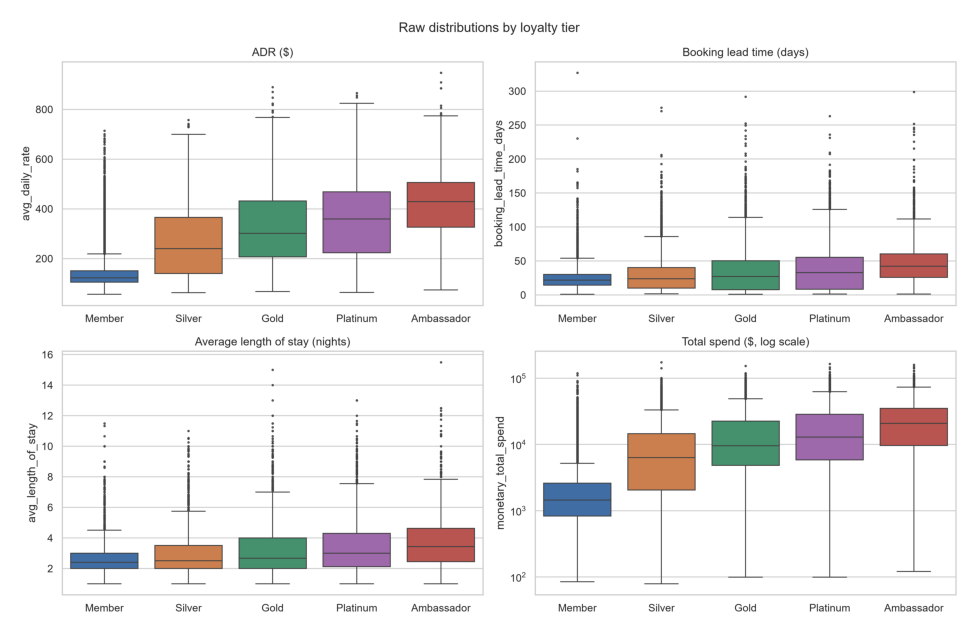

2026-11-20 11:11:18,976 | INFO    | segmentation | Saved D:\Ramakrishna_D\Python\GitProjects\machinelearning\customer_segmentation\output\data_visualizations\booking_channel_breakdown.png


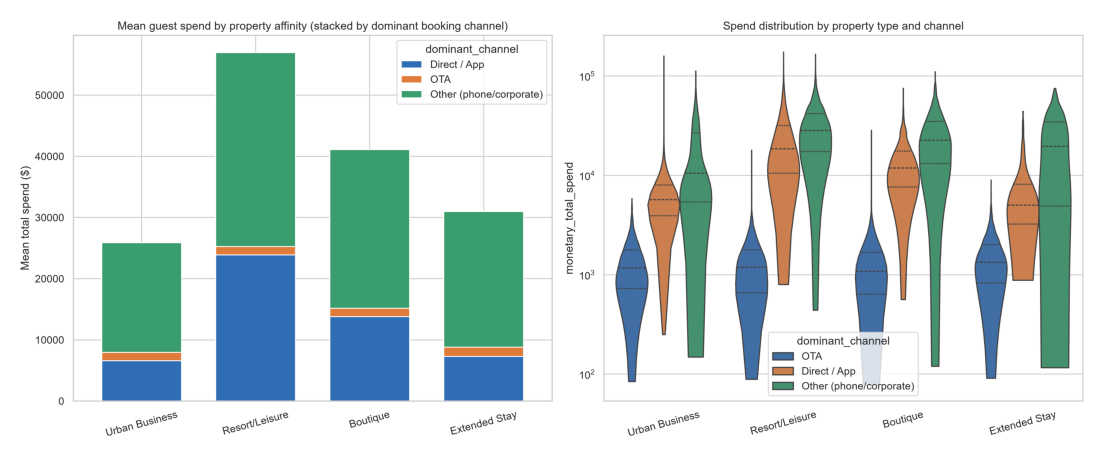

2026-11-20 11:11:20,120 | INFO    | segmentation | Saved D:\Ramakrishna_D\Python\GitProjects\machinelearning\customer_segmentation\output\feature_visualizations\feature_correlation_heatmap.png


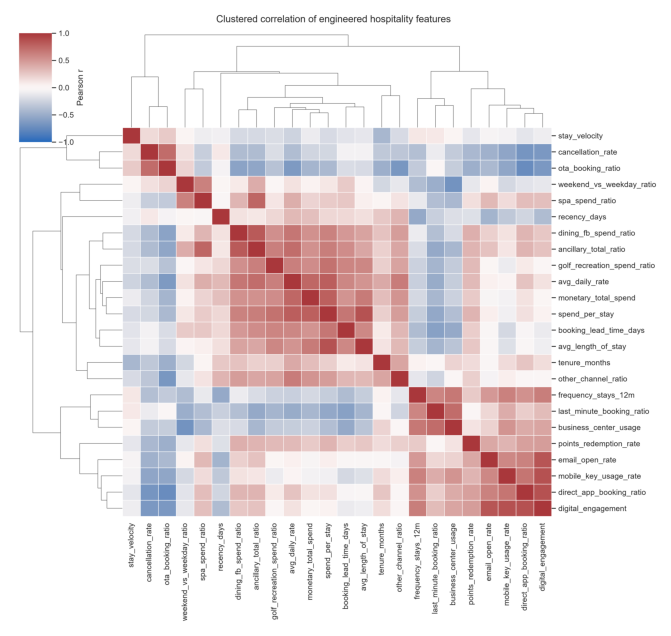

In [13]:
dv, fv = out_dir(cfg, "data_visualizations"), out_dir(cfg, "feature_visualizations")
import matplotlib.image as mpimg
def show(p):
    plt.figure(figsize=(14, 8)); plt.imshow(mpimg.imread(p)); plt.axis("off"); plt.show()
plot_raw_distributions(gfeat, dv / "raw_distributions.png"); show(dv / "raw_distributions.png")
plot_channel_breakdown(gfeat, dv / "booking_channel_breakdown.png"); show(dv / "booking_channel_breakdown.png")
plot_correlation_heatmap(gfeat, fv / "feature_correlation_heatmap.png"); show(fv / "feature_correlation_heatmap.png")

### 10.3 Choosing K (K-Means / GMM sweep)

In [14]:
sweep = []
for k in cfg["model"]["k_sweep"]:
    km_k = KMeansGPU(k, seed=cfg["seed"], device=device).fit(X); lab = km_k.predict(X)
    mk = cluster_metrics(X, lab, cfg["evaluation"]["silhouette_sample"])
    gm_k = GMMGPU(k, seed=cfg["seed"], device=device).fit(X)
    sweep.append(dict(k=k, inertia=km_k.inertia_, silhouette=mk["silhouette"], davies_bouldin=mk["davies_bouldin"],
                      calinski_harabasz=mk["calinski_harabasz"], gmm_bic=gm_k.bic(len(X), X.shape[1])))
    audit.info("K-SWEEP k=%d | %s", k, sweep[-1])
pd.DataFrame(sweep).round(3)

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,gmm_bic
0,3,333970.469,0.370,1.119,12725.919,1088948.736
1,4,276067.125,0.349,1.252,12010.577,848172.270
2,5,270748.500,0.269,1.989,9308.145,772288.048
3,6,240211.438,0.250,1.869,9027.771,624631.680
4,7,236421.891,0.244,2.226,7710.292,525787.033
5,8,231643.375,0.168,2.391,6819.130,410450.545


### 10.4 Train the six models

In [15]:
entries = []; n_inf = min(5000, len(X)); Xi = X[:n_inf]
def refit_factory(space, make):
    return lambda idx, seed: make(seed).fit(space[idx]).predict(space)

# 1. K-Means
with timed("train K-Means", log):
    t = time.perf_counter(); km = KMeansGPU(K, seed=cfg["seed"], device=device).fit(X); sync(); tt = time.perf_counter() - t
lab_km = km.predict(X)
entries.append(dict(name="K-Means (GPU)", paradigm="Centroid", labels=lab_km, space=X, train_time_s=tt,
                    refit_fn=refit_factory(X, lambda s: KMeansGPU(K, seed=s, device=device)), infer_fn=lambda: km.predict(Xi)))
km.save(saved / "kmeans.joblib")
# 2. GMM
with timed("train GMM", log):
    t = time.perf_counter(); gmm = GMMGPU(K, seed=cfg["seed"], device=device).fit(X); sync(); tt = time.perf_counter() - t
lab_gmm = gmm.predict(X)
entries.append(dict(name="GMM (GPU EM)", paradigm="Probabilistic", labels=lab_gmm, space=X, train_time_s=tt,
                    refit_fn=refit_factory(X, lambda s: GMMGPU(K, seed=s, device=device)), infer_fn=lambda: gmm.predict_proba(Xi)))
gmm.save(saved / "gmm.joblib")
# 3. HDBSCAN
with timed("train HDBSCAN", log):
    t = time.perf_counter(); hdb = HDBSCANModel(min_cluster_size=max(50, len(X) // 150), seed=cfg["seed"]).fit(X); tt = time.perf_counter() - t
lab_h = hdb.labels_
audit.info("HDBSCAN found %d clusters; noise/VIP ratio %.2f%%", len(hdb.cluster_ids_), 100 * (lab_h < 0).mean())
entries.append(dict(name="HDBSCAN", paradigm="Density", labels=lab_h, space=X, train_time_s=tt,
                    refit_fn=lambda idx, s: HDBSCANModel(min_cluster_size=hdb.mcs, seed=s).fit(X[idx]).predict(X),
                    infer_fn=lambda: hdb.predict(Xi)))
hdb.save(saved / "hdbscan.joblib")

2026-11-20 11:11:25,191 | INFO    | segmentation | START train K-Means


2026-11-20 11:11:25,238 | INFO    | segmentation | END   train K-Means (0.05s)


2026-11-20 11:11:25,240 | INFO    | segmentation | START train GMM


2026-11-20 11:11:25,289 | INFO    | segmentation | END   train GMM (0.05s)


2026-11-20 11:11:25,307 | INFO    | segmentation | START train HDBSCAN


2026-11-20 11:11:25,329 | INFO    | segmentation | HDBSCAN: using sklearn.cluster.HDBSCAN


2026-11-20 11:11:33,098 | INFO    | segmentation | END   train HDBSCAN (7.79s)


2026-11-20 11:11:33,110 | INFO    | segmentation | START train DEC autoencoder


2026-11-20 11:11:35,876 | INFO    | segmentation | [DEC-pretrain] epoch 1/40 mse=0.34739 (0.78s)


2026-11-20 11:11:40,389 | INFO    | segmentation | [DEC-pretrain] epoch 11/40 mse=0.13486 (0.42s)


2026-11-20 11:11:44,857 | INFO    | segmentation | [DEC-pretrain] epoch 21/40 mse=0.12709 (0.55s)


2026-11-20 11:11:49,272 | INFO    | segmentation | [DEC-pretrain] epoch 31/40 mse=0.12488 (0.40s)


2026-11-20 11:11:53,421 | INFO    | segmentation | [DEC-pretrain] epoch 40/40 mse=0.12467 (0.47s)


... (3 outputs left out)

2026-11-20 11:12:04,211 | INFO    | segmentation | [DEC-finetune] epoch 31/40 total=0.14361 recon=0.12465 kl=0.18954


2026-11-20 11:12:06,911 | INFO    | segmentation | [DEC-finetune] epoch 40/40 total=0.14135 recon=0.12396 kl=0.17391


2026-11-20 11:12:06,912 | INFO    | segmentation | END   train DEC autoencoder (33.80s)


2026-11-20 11:12:07,235 | INFO    | segmentation | Saved D:\Ramakrishna_D\Python\GitProjects\machinelearning\customer_segmentation\output\training_losses\dec_autoencoder_loss.png


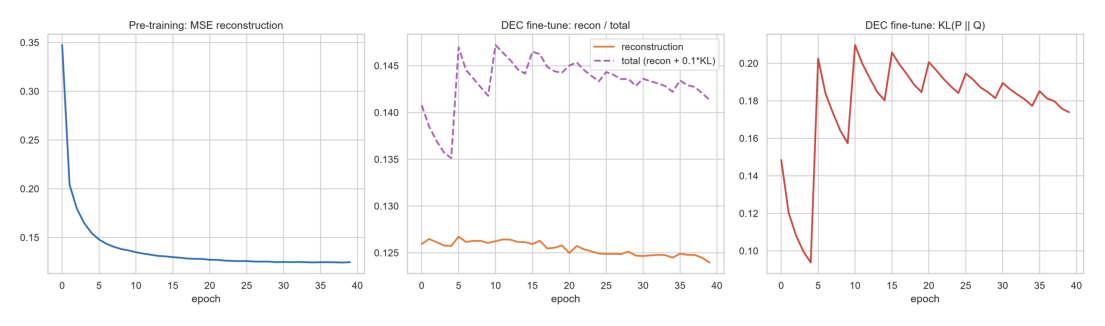

In [16]:
# 4. DEC autoencoder
with timed("train DEC autoencoder", log):
    t = time.perf_counter(); dec, h_dec = train_dec(X, K, device, cfg, metrics, cfg["seed"]); sync(); tt = time.perf_counter() - t
lab_dec, q_dec, Z_dec = dec_predict(dec, X, device)
entries.append(dict(name="DEC Autoencoder", paradigm="Deep", labels=lab_dec, space=Z_dec, train_time_s=tt,
                    refit_fn=refit_factory(Z_dec, lambda s: KMeansGPU(K, seed=s, device=device)),
                    infer_fn=lambda: dec_predict(dec, Xi, device)))
save_dec(dec, saved / "dec_autoencoder.pt")
tl = out_dir(cfg, "training_losses")
plot_dec_loss(h_dec, tl / "dec_autoencoder_loss.png"); show(tl / "dec_autoencoder_loss.png")

2026-11-20 11:12:07,542 | INFO    | segmentation | START train beta-VAE


2026-11-20 11:12:07,914 | INFO    | segmentation | [beta-VAE] epoch 1/60 elbo=17.072 recon=16.491 kl=5.809 beta=0.10


2026-11-20 11:12:11,203 | INFO    | segmentation | [beta-VAE] epoch 11/60 elbo=12.654 recon=8.252 kl=4.002 beta=1.10


2026-11-20 11:12:14,380 | INFO    | segmentation | [beta-VAE] epoch 21/60 elbo=14.654 recon=9.694 kl=2.480 beta=2.00


2026-11-20 11:12:17,474 | INFO    | segmentation | [beta-VAE] epoch 31/60 elbo=14.316 recon=9.576 kl=2.370 beta=2.00


2026-11-20 11:12:20,662 | INFO    | segmentation | [beta-VAE] epoch 41/60 elbo=14.226 recon=9.471 kl=2.378 beta=2.00


2026-11-20 11:12:23,470 | INFO    | segmentation | [beta-VAE] epoch 51/60 elbo=14.138 recon=9.429 kl=2.355 beta=2.00


2026-11-20 11:12:25,725 | INFO    | segmentation | [beta-VAE] epoch 60/60 elbo=14.129 recon=9.377 kl=2.376 beta=2.00


2026-11-20 11:12:25,782 | INFO    | segmentation | END   train beta-VAE (18.24s)


2026-11-20 11:12:26,107 | INFO    | segmentation | Saved D:\Ramakrishna_D\Python\GitProjects\machinelearning\customer_segmentation\output\training_losses\beta_vae_loss.png


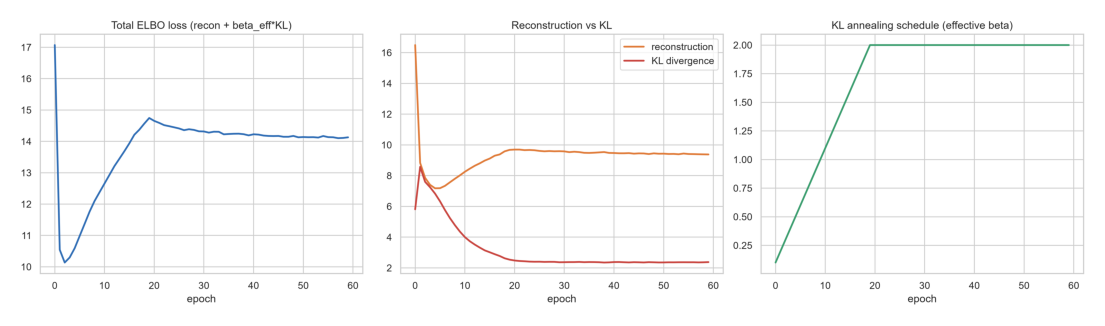

In [17]:
# 5. beta-VAE
with timed("train beta-VAE", log):
    t = time.perf_counter(); vae, h_vae = train_vae(X, device, cfg, metrics)
    mu = vae_latents(vae, X, device); km_v = KMeansGPU(K, seed=cfg["seed"], device=device).fit(mu); sync(); tt = time.perf_counter() - t
lab_vae = km_v.predict(mu)
entries.append(dict(name="Beta-VAE + K-Means", paradigm="Deep generative", labels=lab_vae, space=mu, train_time_s=tt,
                    refit_fn=refit_factory(mu, lambda s: KMeansGPU(K, seed=s, device=device)),
                    infer_fn=lambda: km_v.predict(vae_latents(vae, Xi, device))))
km_v.save(saved / "beta_vae_kmeans.joblib"); save_vae(vae, saved / "beta_vae.pt", "beta_vae_kmeans.joblib")
plot_vae_loss(h_vae, tl / "beta_vae_loss.png"); show(tl / "beta_vae_loss.png")

2026-11-20 11:12:26,420 | INFO    | segmentation | START train Sequence Transformer


2026-11-20 11:12:27,288 | INFO    | segmentation | [SeqTransformer] epoch 1/25 train=0.9211 val=0.7631


2026-11-20 11:12:30,232 | INFO    | segmentation | [SeqTransformer] epoch 6/25 train=0.5185 val=0.4777


2026-11-20 11:12:33,136 | INFO    | segmentation | [SeqTransformer] epoch 11/25 train=0.4617 val=0.4419


2026-11-20 11:12:36,036 | INFO    | segmentation | [SeqTransformer] epoch 16/25 train=0.4377 val=0.4164


2026-11-20 11:12:38,983 | INFO    | segmentation | [SeqTransformer] epoch 21/25 train=0.4260 val=0.4075


2026-11-20 11:12:41,325 | INFO    | segmentation | [SeqTransformer] epoch 25/25 train=0.4244 val=0.4062


2026-11-20 11:12:41,394 | INFO    | segmentation | END   train Sequence Transformer (14.97s)


2026-11-20 11:12:41,540 | INFO    | segmentation | Saved D:\Ramakrishna_D\Python\GitProjects\machinelearning\customer_segmentation\output\training_losses\sequence_transformer_loss.png


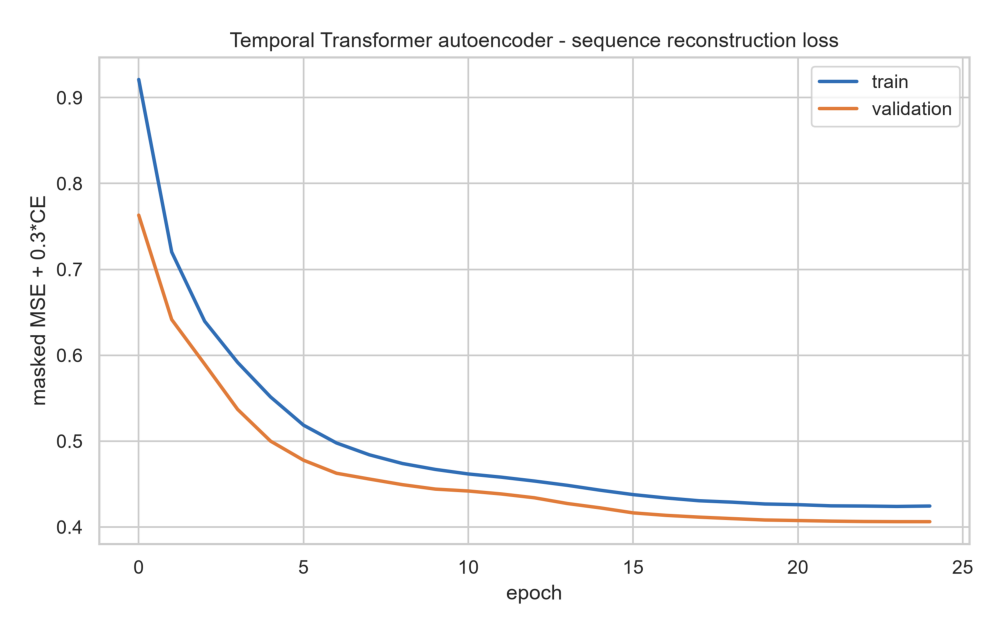

In [18]:
# 6. Sequence Transformer
with timed("train Sequence Transformer", log):
    t = time.perf_counter(); stm, h_seq = train_seq(cont, prop, m, device, cfg, metrics, cfg["seed"])
    E = seq_embeddings(stm, cont, prop, m, device); km_s = KMeansGPU(K, seed=cfg["seed"], device=device).fit(E); sync(); tt = time.perf_counter() - t
lab_seq = km_s.predict(E)
entries.append(dict(name="Sequence Transformer", paradigm="Sequential", labels=lab_seq, space=E, train_time_s=tt,
                    refit_fn=refit_factory(E, lambda s: KMeansGPU(K, seed=s, device=device)),
                    infer_fn=lambda: km_s.predict(seq_embeddings(stm, cont[:n_inf], prop[:n_inf], m[:n_inf], device))))
km_s.save(saved / "sequence_kmeans.joblib"); save_seq(stm, saved / "sequence_transformer.pt")
plot_seq_loss(h_seq, tl / "sequence_transformer_loss.png"); show(tl / "sequence_transformer_loss.png")
for e in entries: e["can_serve"] = bool(len(set(e["labels"]) - {-1}) >= K)

### 10.5 Evaluate, compare and select the winner

In [19]:
with timed("evaluation", log):
    df = compare_models(entries, X, gfeat, cfg)
    best_name = select_best(df, cfg)
best = next(e for e in entries if e["name"] == best_name); best_labels = best["labels"]
log.info("Selected production model: %s", best_name)
df.drop(columns=["can_serve"]).round(4).sort_values("composite_rank_score")

2026-11-20 11:12:41,743 | INFO    | segmentation | START evaluation


2026-11-20 11:12:46,307 | INFO    | segmentation | HDBSCAN: using sklearn.cluster.HDBSCAN


2026-11-20 11:12:48,816 | INFO    | segmentation | HDBSCAN: using sklearn.cluster.HDBSCAN


2026-11-20 11:12:53,160 | INFO    | segmentation | HDBSCAN: using sklearn.cluster.HDBSCAN


2026-11-20 11:12:57,278 | INFO    | segmentation | HDBSCAN: using sklearn.cluster.HDBSCAN


2026-11-20 11:13:03,537 | INFO    | segmentation | HDBSCAN: using sklearn.cluster.HDBSCAN


2026-11-20 11:13:16,954 | INFO    | segmentation | END   evaluation (35.21s)


2026-11-20 11:13:16,955 | INFO    | segmentation | Selected production model: DEC Autoencoder


,model,paradigm,silhouette,davies_bouldin,calinski_harabasz,n_clusters,noise_ratio,latent_silhouette,stability_ari,train_time_ms,inference_latency_ms,ari_vs_planted_archetypes,composite_rank_score
2,HDBSCAN,Density,0.3687,1.1169,12808.7735,3,0.0036,0.3687,0.9935,7790.5587,1.3652,0.4691,1.50
3,DEC Autoencoder,Deep,0.3428,1.3407,10838.5628,5,0.0000,0.7600,0.9999,33800.9204,2.1612,0.7753,1.75
4,Beta-VAE + K-Means,Deep generative,0.3416,1.3413,10749.3348,5,0.0000,0.5730,0.9998,18239.1792,2.4940,0.7712,2.75
0,K-Means (GPU),Centroid,0.2694,1.9891,9308.1445,5,0.0000,0.2694,0.7580,46.0891,0.4063,0.5846,4.25
1,GMM (GPU EM),Probabilistic,0.2037,3.5053,8112.3326,5,0.0000,0.2037,0.7368,48.2302,0.3165,0.5674,5.25
5,Sequence Transformer,Sequential,0.0998,3.8791,4570.4522,5,0.0000,0.2488,0.9638,14973.7653,32.8001,0.3771,5.50


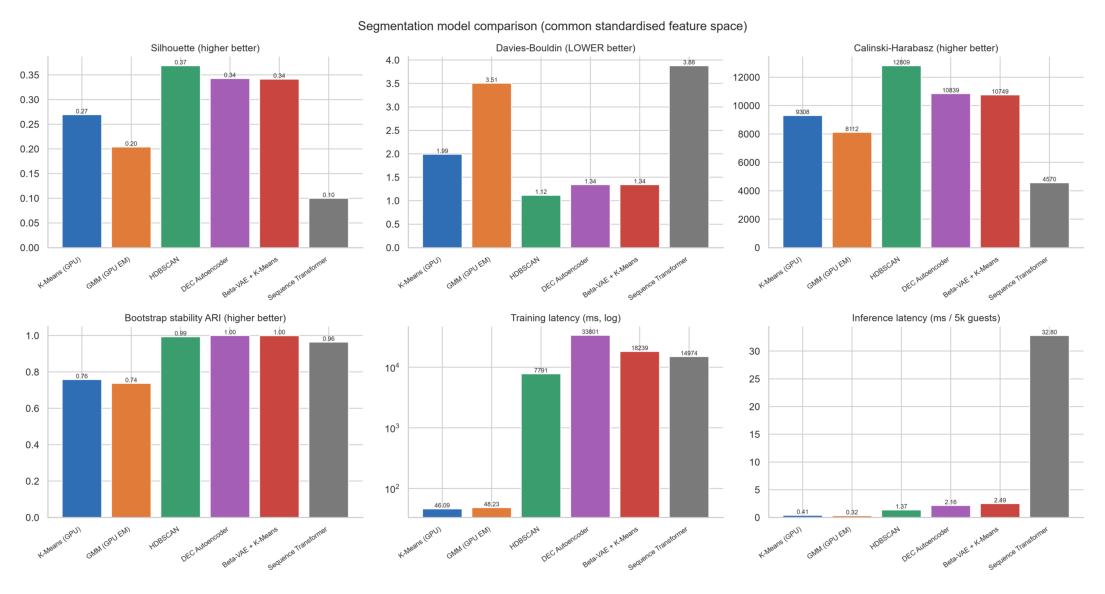

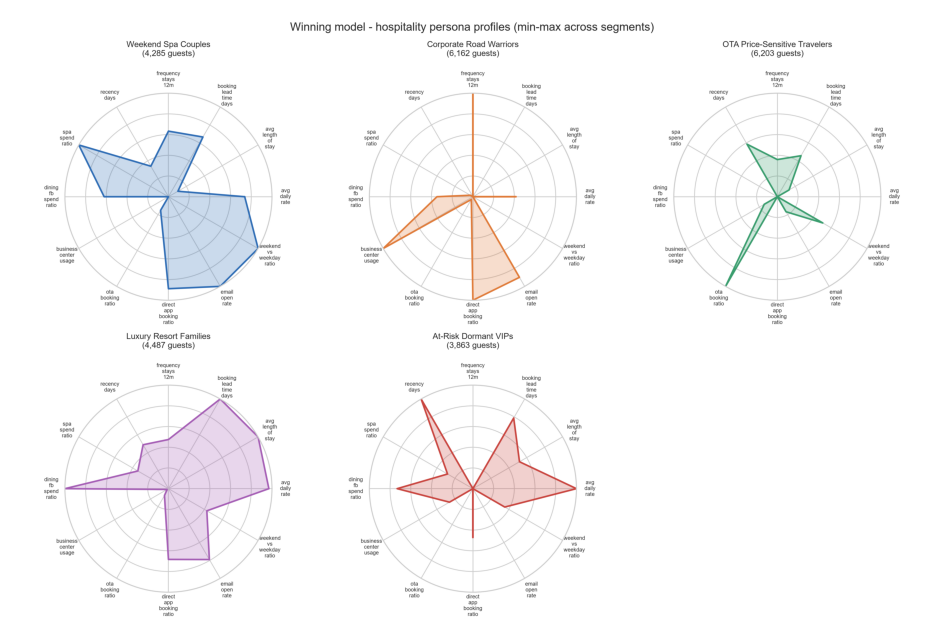

,segment_id,segment_name,size,share_pct,avg_ltv,avg_total_spend,avg_adr,avg_los,avg_lead_time,avg_recency_days,churn_risk,next_best_offer
0,0,Weekend Spa Couples,4285,17.14,21563.26,12612.40,336.66,2.45,35.6,69.8,0.167,Couples spa package + weekend stay
1,1,Corporate Road Warriors,6162,24.65,14979.69,6149.10,213.09,2.17,7.0,24.3,0.063,Corporate rate + guaranteed late checkout
2,2,OTA Price-Sensitive Travelers,6203,24.81,1626.05,1380.07,117.63,2.55,22.7,148.8,0.310,Member-only direct rate + 500 bonus points
3,3,Luxury Resort Families,4487,17.95,45984.28,32794.90,468.91,5.62,77.2,110.8,0.246,Suite upgrade + family dining credit
4,4,At-Risk Dormant VIPs,3863,15.45,7563.74,31808.22,489.56,3.64,46.2,519.7,0.658,Status-match + win-back points bonus


In [20]:
mapping, prof = name_clusters(X, best_labels, cfg)
audit.info("PERSONA MAPPING (winner %s): %s", best_name, mapping)
kpis = segment_kpis(gfeat, best_labels, mapping, cfg)
mc = out_dir(cfg, "model_comparisons")
plot_metric_comparison(df, mc / "metrics_comparison_bar.png"); show(mc / "metrics_comparison_bar.png")
ids = [c for c in np.unique(best_labels) if c >= 0]; sizes = [int((best_labels == c).sum()) for c in ids]
plot_radar(prof, [mapping[c] for c in ids], sizes, mc / "cluster_radar_personas.png"); show(mc / "cluster_radar_personas.png")
save_benchmark(df, kpis, mc, best_name)
kpis.drop(columns=["playbook"])

### 10.6 Feature importance and latent-space projections

2026-11-20 11:13:23,171 | INFO    | segmentation | Saved D:\Ramakrishna_D\Python\GitProjects\machinelearning\customer_segmentation\output\feature_visualizations\feature_importance_anova.png


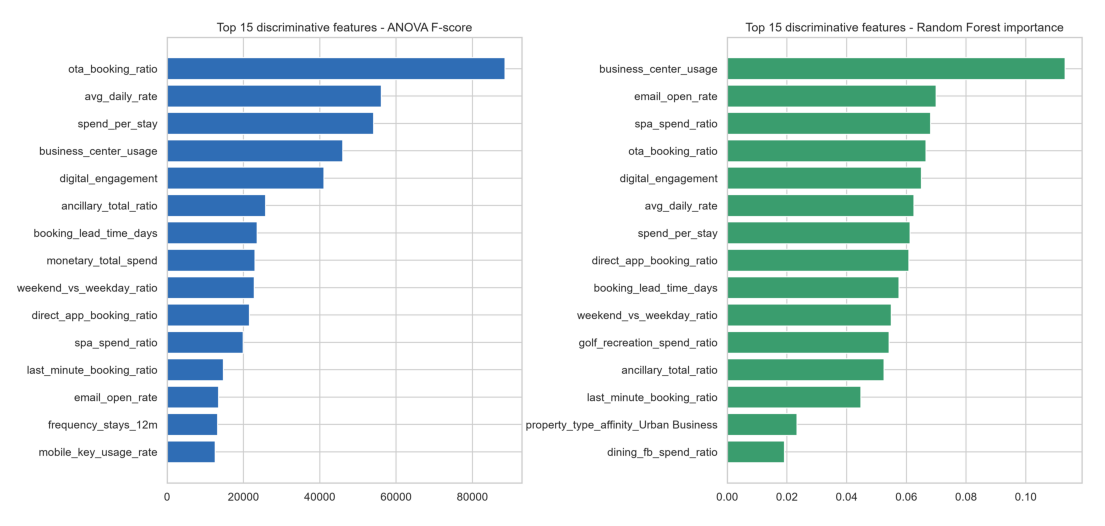

2026-11-20 11:13:38,979 | INFO    | segmentation | Saved D:\Ramakrishna_D\Python\GitProjects\machinelearning\customer_segmentation\output\feature_visualizations\latent_space_umap.png


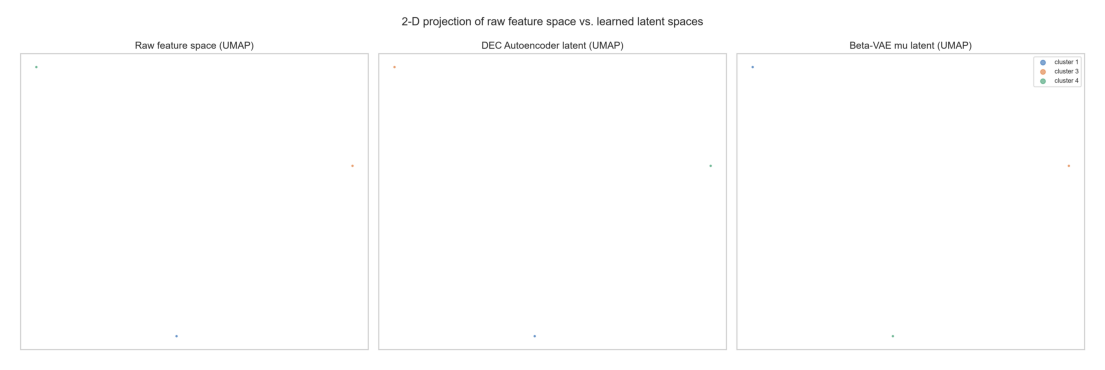

In [21]:
plot_feature_importance(X, best_labels, fp.feature_names_, fv / "feature_importance_anova.png", seed=cfg["seed"]); show(fv / "feature_importance_anova.png")
plot_latent_umap({"Raw feature space": X, "DEC Autoencoder latent": Z_dec, "Beta-VAE mu latent": mu},
                 {"Raw feature space": lab_km, "DEC Autoencoder latent": lab_dec, "Beta-VAE mu latent": lab_vae},
                 fv / "latent_space_umap.png", seed=cfg["seed"]); show(fv / "latent_space_umap.png")

### 10.7 Save registry and segmented guests

In [22]:
from sklearn.decomposition import PCA
joblib.dump(PCA(3, random_state=cfg["seed"]).fit(X), saved / "pca_viz.joblib")
artefacts = {"K-Means (GPU)": ("kmeans", "kmeans.joblib"), "GMM (GPU EM)": ("gmm", "gmm.joblib"),
             "HDBSCAN": ("hdbscan", "hdbscan.joblib"), "DEC Autoencoder": ("dec", "dec_autoencoder.pt"),
             "Beta-VAE + K-Means": ("beta_vae_kmeans", "beta_vae.pt"), "Sequence Transformer": ("sequence_kmeans", "sequence_transformer.pt")}
mtype, mfile = artefacts[best_name]; brow = df[df.model == best_name].iloc[0]
registry = {"best_model": best_name, "model_type": mtype, "model_file": mfile,
    "cluster_file": {"beta_vae_kmeans": "beta_vae_kmeans.joblib", "sequence_kmeans": "sequence_kmeans.joblib"}.get(mtype),
    "version": dt.datetime.now().strftime("%Y%m%d-%H%M%S"), "trained_at": dt.datetime.now().isoformat(),
    "n_clusters": int(len(ids)), "n_features": int(X.shape[1]), "feature_names": fp.feature_names_,
    "segment_names": {str(k): v for k, v in mapping.items()},
    "metrics": {k: (None if pd.isna(brow[k]) else float(brow[k])) for k in ["silhouette", "davies_bouldin", "calinski_harabasz", "stability_ari"]},
    "preprocessing": {"scaler": "scaler.joblib", "encoder": "encoder.joblib", "pipeline": "feature_pipeline.joblib",
                      "sequence_normalizer": "sequence_normalizer.joblib", "pca_viz": "pca_viz.joblib"},
    "vip_outlier_detector": "hdbscan.joblib", "all_models": {k: v[1] for k, v in artefacts.items()}}
json.dump(registry, open(saved / "model_registry.json", "w", encoding="utf-8"), indent=2)
kpis.to_json(saved / "segment_personas.json", orient="records", indent=2)
seg = guests.copy(); seg["segment_id"] = best_labels; seg["segment_name"] = seg.segment_id.map(mapping)
seg.to_csv(ROOT / cfg["paths"]["data"] / "guests_segmented.csv", index=False)
log.info("Pipeline finished in %.1fs. Winner: %s", time.perf_counter() - T0, best_name)
log_gpu_memory("end", log)

2026-11-20 11:13:40,045 | INFO    | segmentation | Pipeline finished in 148.6s. Winner: DEC Autoencoder


2026-11-20 11:13:40,047 | INFO    | segmentation | GPU mem [end]: allocated 0.8 MB | reserved 323.0 MB


### 10.8 Artifact check

In [23]:
need = ["logs/pipeline_execution.log", "logs/training_metrics.jsonl", "logs/evaluation_audit.log",
 "data_visualizations/raw_distributions.png", "data_visualizations/booking_channel_breakdown.png",
 "feature_visualizations/feature_correlation_heatmap.png", "feature_visualizations/feature_importance_anova.png",
 "feature_visualizations/latent_space_umap.png", "training_losses/dec_autoencoder_loss.png",
 "training_losses/beta_vae_loss.png", "training_losses/sequence_transformer_loss.png",
 "model_comparisons/metrics_comparison_bar.png", "model_comparisons/cluster_radar_personas.png",
 "model_comparisons/model_benchmark_summary.csv", "model_comparisons/model_benchmark_summary.json",
 "saved_models/scaler.joblib", "saved_models/encoder.joblib", "saved_models/model_registry.json"]
base = out_dir(cfg)
missing = [n for n in need if not (base / n).exists()]
print("All required artifacts present" if not missing else f"MISSING: {missing}")

All required artifacts present
